# Drum-wise PCA + PC algorithm + T²

`config -> load + clean -> flare masking -> per-drum PCA -> PC algorithm -> graph -> T²`

Code marked **[TA]** is copied from `references/CodeByTA/flare_pca_sfa_monitor_4windows_v2.ipynb`
(the reference pipeline; it is not modified). Drum grouping comes from `unit_drum_grouping/drum_tags.json`
and `unit_drums.json`. Unit renames (ISOM2→LPG, ISOM4→DHT, NSU_NHT_CCR→CCR, APS_NVPS_LEU→CDU) are applied
in memory at load time; raw parquet files are only read.

## Config

In [1]:
import glob
import hashlib
import json
import os
import pickle
import re
import sys
import time
import warnings
from functools import reduce
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)   # TA loader joins tag by tag

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 50)

# ---- paths ----
# Works from any folder inside the repo. Dataset_HPCL may sit inside the repo or next to it (lab layout).
_up = [Path.cwd(), *Path.cwd().parents]
REPO = next((p for p in _up if (p / "unit_drum_grouping").is_dir()), None)
DATA_DIR = next((p / "Dataset_HPCL" for p in _up if (p / "Dataset_HPCL").is_dir()), None)
assert REPO is not None, "run from inside the repository (no parent folder holds unit_drum_grouping/)"
assert DATA_DIR is not None, "Dataset_HPCL/ not found in this folder or any parent folder"
GROUPING_DIR = REPO / "unit_drum_grouping"
# DRUM_PC_OUT (environment variable) redirects all outputs, e.g. for a test run
OUT_DIR = Path(os.environ["DRUM_PC_OUT"]) if os.environ.get("DRUM_PC_OUT") else REPO / "drum_pca_pc" / "outputs"
CKPT_DIR = OUT_DIR / "checkpoints"
# Replaced by vectorized_pc (imported in the Step 4 'vectorized PC' cell):
# [old PC] sys.path.insert(0, str(REPO / "drum_pca_pc"))
# [old PC] import pc_fast                     # PC algorithm (Step 4), same rules as causal-learn, see pc_fast.py
UNIT_RENAME = {"ISOM_2": "LPG", "ISOM_4": "DHT", "NSU_NHT_CCR": "CCR", "APS_NVPS_LEU": "CDU"}  # folder -> unit

# ---- [TA] data / cleaning ----
FLARE_FOLDER = "flare_data"
SKIP_ROWS = 58677                  # [TA] rows dropped at the start of every folder
TS = "Timestamp"
FLOW = "Flare_Flowrate"
MAX_MISSING_PCT = 10               # [TA] clean_and_impute default (process tags)
FLARE_MAX_MISSING_PCT = 50         # [TA] value used for the flare folder
SLOPE_STD_THRESHOLD = 1e-10        # [TA]
SCREEN_MIN_STD, SCREEN_MAX_MISSING, SCREEN_MAX_FLAT = 1e-3, 0.05, 0.999   # [TA] build_unit_matrix

# ---- [TA] flare events ----
THRESHOLD = 1.5                    # MT/h, flow >= THRESHOLD
MIN_DURATION_MIN = 30              # sustained at least this long
MERGE_GAP_MIN = 0                  # 0 -> strictly continuous

# ---- this notebook ----
FLARE_PRE_WINDOW_MIN = 60          # minutes before a flare start that are also removed
PCA_VARIANCE_THRESHOLD = 0.80      # smallest k with cumulative explained variance >= this
PC_ALPHA = 0.01                    # Fisher-z significance level of the PC algorithm
PC_ROW_STEP = 10                   # PC algorithm uses every n-th normal-operation row
PC_MAX_K = 1                       # largest conditioning set (pc_fast supports 0 or 1; the lab run used 1)
MEEK_MAX_PASSES = 300              # Meek rules stop after this many passes (a warning is printed)
STAGE_TIME_LIMIT_S = 300           # a Step-4 stage whose estimate exceeds this is not started; Meek stops at it
FORCE_RERUN = False                # True: ignore all checkpoints and recompute everything
COLLINEAR_R = 0.999                # |r| >= this between two PCs: the second one is not passed to PC
EIG_MIN = 1e-6                     # PCs dropped until the correlation matrix's smallest eigenvalue >= this
STD_FLOOR = 1e-4                   # [TA] sd <= this on normal data -> near-zero-variance tag, dropped
SD_REL_MIN = 0.1                   # [TA] sd floored at SD_REL_MIN x long-run sd
USE_Z_CLIP, Z_CLIP = False, 50.0   # [TA] optional |z| cap (off)
T2_DTYPE = "float32"               # storage precision of the saved T² files
PLOT_RESAMPLE = "60min"            # T² plots show the max per bin
N_EXAMPLE_PLOTS = 3                # figures shown inline (all are saved)
EPS = 1e-12

# ---- moving-window T2, thresholds, detection, evaluation, root cause ----
T2_WINDOW_SIZE = 2                 # trailing moving-window length (consecutive samples, no look-ahead)
MAX_GAP_FACTOR = 2.0               # NaN window if timestamp step > sampling_interval * MAX_GAP_FACTOR
T2_THRESHOLD_METHOD = "empirical"  # "empirical" (normal-op percentile) or "ucl" (F / chi2 UCL)
T2_THRESHOLD_PERCENTILE = 99       # percentile (0-100) for empirical threshold & (1 - alpha)*100 for UCL
T2_UCL_DIST = "F"                  # "F" (Hotelling F) or "chi2" (chi-square) when T2_THRESHOLD_METHOD == "ucl"
MIN_EXCEED_SAMPLES = 1             # consecutive samples > threshold inside pre-flare window to signal
EXCLUDE_FLARE_FROM_PRE_WINDOW = True  # exclude timestamps inside an earlier flare from pre-flare window
USE_MEAN_SHIFT_SIGNAL = False      # optional alternative: pre-flare T2 mean > preceding baseline (Welch t-test)
BASELINE_WINDOW_MIN = 120          # preceding normal-data baseline length (min) for mean-shift test
MEAN_SHIFT_ALPHA = 0.01            # significance level for one-sided Welch t-test
MIN_DRUMS_SIGNALING = 1            # plant-level detection requires at least this many drums signaling
ALARM_MERGE_MIN = 5                # merge normal-period exceedance runs separated by < this many minutes
SENSITIVITY_PERCENTILES = (95, 97.5, 99, 99.5)
SENSITIVITY_WINDOWS = (1, 2, 3, 5)
TOP_K_DRUMS = 3                    # top drums ranked per flare
TOP_K_TAGS = 3                     # top tags ranked per top drum
N_EXAMPLE_ZOOM_PLOTS = 2           # number of TP and FN example flare zoom-in plots each
ZOOM_BEFORE_MIN = 90               # minutes before flare start in zoom-in plots
ZOOM_AFTER_MIN = 60                # minutes after flare start in zoom-in plots

print("repository:", REPO, "| data:", DATA_DIR, "| outputs:", OUT_DIR)
for sub in ("graphs_json", "graphs_png", "t2", "t2_plots", "checkpoints"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)


# ---- checkpoints ----
# Each checkpoint stores a hash of every setting (and the input files) it depends on. It is reused only when
# the hash matches, so changing e.g. PC_ALPHA recomputes Step 4b onwards but keeps the PCA models.
def _sig(*parts):
    return hashlib.sha1(json.dumps(parts, sort_keys=True, default=str).encode()).hexdigest()[:16]


DATA_SIG = _sig(sorted((str(f.relative_to(DATA_DIR)), f.stat().st_size) for f in DATA_DIR.glob("*/*.parquet")),
                (GROUPING_DIR / "drum_tags.json").read_text(), (GROUPING_DIR / "unit_drums.json").read_text())
H_PCA = _sig(DATA_SIG, SKIP_ROWS, MAX_MISSING_PCT, FLARE_MAX_MISSING_PCT, SLOPE_STD_THRESHOLD, SCREEN_MIN_STD,
             SCREEN_MAX_MISSING, SCREEN_MAX_FLAT, THRESHOLD, MIN_DURATION_MIN, MERGE_GAP_MIN, FLARE_PRE_WINDOW_MIN,
             PCA_VARIANCE_THRESHOLD, STD_FLOOR, SD_REL_MIN, USE_Z_CLIP, Z_CLIP, UNIT_RENAME)
H_PC_INPUT = _sig(H_PCA, PC_ROW_STEP, COLLINEAR_R, EIG_MIN)
H_SKELETON = _sig(H_PC_INPUT, PC_ALPHA, PC_MAX_K)
H_GRAPH = _sig(H_SKELETON, MEEK_MAX_PASSES, STAGE_TIME_LIMIT_S)
H_T2 = _sig(H_PCA, T2_DTYPE, T2_WINDOW_SIZE, MAX_GAP_FACTOR)
H_T2_PLOTS = _sig(H_T2, PLOT_RESAMPLE, T2_THRESHOLD_METHOD, T2_THRESHOLD_PERCENTILE, T2_UCL_DIST)


def ckpt_load(name, h):
    f = CKPT_DIR / f"{name}.pkl"
    if FORCE_RERUN or not f.exists():
        return None
    with open(f, "rb") as fh:
        obj = pickle.load(fh)
    if obj.get("hash") != h:
        print(f"checkpoint {name}: settings or data changed -> recomputing")
        return None
    print(f"checkpoint {name}: reused ({f.stat().st_size / 1e6:.1f} MB, saved {obj['saved']})")
    return obj["data"]


def ckpt_save(name, h, data):
    f = CKPT_DIR / f"{name}.pkl"
    with open(f, "wb") as fh:
        pickle.dump({"hash": h, "saved": time.strftime("%Y-%m-%d %H:%M"), "data": data}, fh,
                    protocol=pickle.HIGHEST_PROTOCOL)
    print(f"checkpoint {name}: saved ({f.stat().st_size / 1e6:.1f} MB)")


def marker_ok(folder, h):
    """True if files in folder were written with the current settings (per-file reuse of T² outputs)."""
    m = folder / "_settings_hash.txt"
    return not FORCE_RERUN and m.exists() and m.read_text().strip() == h


RUN_T0 = time.time()
STAGE_TIMES = {}

repository: d:\Root-Cause-Detection | data: d:\Dataset_HPCL | outputs: d:\Root-Cause-Detection\drum_pca_pc\outputs


## Step 0 - Inspect the flare data and the sampling interval

In [2]:
rows = []
for f in sorted((DATA_DIR / FLARE_FOLDER).glob("*.parquet")):
    d = pd.read_parquet(f)
    t = d[TS]
    steps = t.diff().value_counts()
    rows.append({"file": f.name, "value_column": [c for c in d.columns if c != TS][0], "rows": len(d),
                 "ts_dtype": str(t.dtype), "tz": str(t.dt.tz), "start": t.min(), "end": t.max(),
                 "main_step": steps.index[0], "duplicate_ts": int(t.duplicated().sum()),
                 "gaps_>1min": int((t.diff() > pd.Timedelta(minutes=1)).sum()),
                 "largest_gap": t.diff().max(), "min": d.iloc[:, 1].min(), "max": d.iloc[:, 1].max()})
flare_files = pd.DataFrame(rows)
print("Flare folder:")
display(flare_files)
print("Flare flow used (as in the TA notebook): Flare_Flowrate = 509fi5201.daca.pv/1000 "
      "+ (LRflare+LREflare+99fi4601)/1000 - (44ft2505*509mw5101/22.414)/1000  [MT/h]")
print("Coverage: one refinery-wide flare flow; nothing in the files ties a flare to a unit -> mask applied globally.")

# sampling interval of the process data (raw files, before the 1-min grid)
proc_files = sorted(f for f in DATA_DIR.glob("*/*.parquet") if f.parent.name != FLARE_FOLDER)
step_counts = pd.Series(dtype=float)
for f in proc_files[:: max(1, len(proc_files) // 25)]:
    step_counts = step_counts.add(pd.read_parquet(f, columns=[TS])[TS].diff().value_counts(), fill_value=0)
print(f"\nProcess data: {len(proc_files)} tag files. Sampling steps in a sample of "
      f"{len(proc_files[:: max(1, len(proc_files) // 25)])} files:")
print(step_counts.sort_values(ascending=False).head(5).astype(int).to_string())

Flare folder:


,file,value_column,rows,ts_dtype,tz,start,end,main_step,duplicate_ts,gaps_>1min,largest_gap,min,max
0,(44ft2505.pv_509mw5101.daca.pv_22.414)_1000.pa...,(44ft2505.pv*509mw5101.daca.pv/22.414)/1000,492492,datetime64[us],None,2025-04-12,2026-05-21,0 days 00:01:00,9,2,31 days 00:00:00,0.00,4.35
1,(LRflare.pv+LREflare.pv+99fi4601.daca.pv)_1000...,(LRflare.pv+LREflare.pv+99fi4601.daca.pv)/1000,537133,datetime64[us],None,2025-04-12,2026-05-21,0 days 00:01:00,11,1,31 days 00:00:00,0.00,7.54
2,509fi5201.daca.pv_1000.parquet,509fi5201.daca.pv/1000,581774,datetime64[us],None,2025-04-12,2026-05-21,0 days 00:01:00,13,0,0 days 00:01:00,0.00,50.06
3,509mw5101.daca.pv.parquet,509mw5101.daca.pv,452171,datetime64[us],None,2025-04-12,2026-05-21,0 days 00:01:00,8,2,59 days 00:00:00,0.01,50.09


Flare flow used (as in the TA notebook): Flare_Flowrate = 509fi5201.daca.pv/1000 + (LRflare+LREflare+99fi4601)/1000 - (44ft2505*509mw5101/22.414)/1000  [MT/h]
Coverage: one refinery-wide flare flow; nothing in the files ties a flare to a unit -> mask applied globally.

Process data: 376 tag files. Sampling steps in a sample of 26 files:
Timestamp
0 days 00:01:00      14601600
0 days 00:00:00           323
31 days 00:00:00            1
120 days 00:00:00           1
122 days 00:00:00           1


## Step 1 - Load and clean (global, before any split by unit/drum)

In [3]:
drum_tags = json.loads((GROUPING_DIR / "drum_tags.json").read_text())
unit_drums = json.loads((GROUPING_DIR / "unit_drums.json").read_text())
DRUM_UNIT = {d: u for u, ds in unit_drums.items() for d in ds}
cv_present = any(v.get("control_valve_tags") for v in drum_tags.values())
print(f"{len(unit_drums)} units, {len(drum_tags)} drums; control_valve_tags in drum_tags.json: "
      f"{'yes' if cv_present else 'none (key absent or empty) -> only process tags are used'}")

FOLDER_OF = {UNIT_RENAME.get(p.name, p.name): p.name for p in DATA_DIR.iterdir()
             if p.is_dir() and p.name != FLARE_FOLDER}
missing_units = set(unit_drums) - set(FOLDER_OF)
assert not missing_units, f"no folder for units {missing_units}"
print("unit -> folder:", {u: FOLDER_OF[u] for u in unit_drums})


# [TA] -------------------------------------------------------------------------
def load_parquet_folder(folder, freq="1min"):
    """All parquet files of one folder -> one DataFrame on a complete time grid."""
    files = glob.glob(os.path.join(folder, "*.parquet"))
    if not files:
        raise ValueError(f"No parquet files found in '{folder}'")
    dfs = []
    for file in files:
        df = pd.read_parquet(file)
        df[TS] = pd.to_datetime(df[TS])
        df = df.drop_duplicates(subset=TS).set_index(TS)
        tag = os.path.splitext(os.path.basename(file))[0]
        dfs.append(df[[df.columns[0]]].rename(columns={df.columns[0]: tag}))
    merged = reduce(lambda a, b: a.join(b, how="outer"), dfs)
    grid = pd.date_range(merged.index.min(), merged.index.max(), freq=freq)
    merged = merged.reindex(grid).rename_axis(TS).reset_index()
    return merged.iloc[SKIP_ROWS:].reset_index(drop=True)


def clean_and_impute(df, max_missing_pct=10, slope_std_threshold=1e-10):
    ts = df[TS]
    x = df.drop(columns=[TS])
    before = x.shape[1]
    x = x.loc[:, x.isna().mean() * 100 <= max_missing_pct]     # gappy
    x = x.loc[:, x.std() > 0]                                  # constant
    x = x.loc[:, x.diff().std() > slope_std_threshold]         # constant slope
    x = x.loc[:, ~(x < 0).any()]                               # negative values
    x = x.interpolate(method="linear", limit_direction="both").ffill().bfill()
    print(f"  {before} tags -> {x.shape[1]} kept")
    return pd.concat([ts.reset_index(drop=True), x.reset_index(drop=True)], axis=1)
# -------------------------------------------------------------------------------


t0 = time.time()
parts = []
for u in unit_drums:                         # unit renamed in memory: column "UNIT::tag"
    d = load_parquet_folder(str(DATA_DIR / FOLDER_OF[u])).set_index(TS)
    d.columns = [f"{u}::{c}" for c in d.columns]
    parts.append(d)
raw_all = pd.concat(parts, axis=1).sort_index().rename_axis(TS).reset_index()   # one global frame
del parts
flare_raw = load_parquet_folder(str(DATA_DIR / FLARE_FOLDER))
print(f"loaded in {time.time() - t0:.0f} s")
print(f"BEFORE cleaning: {raw_all.shape[0]:,} rows x {raw_all.shape[1] - 1} tags "
      f"({raw_all[TS].iloc[0]} -> {raw_all[TS].iloc[-1]}), missing cells {raw_all.isna().mean().mean():.2%}")

13 units, 301 drums; control_valve_tags in drum_tags.json: none (key absent or empty) -> only process tags are used
unit -> folder: {'SEU3': 'SEU3', 'SEU1': 'SEU1', 'SEU2': 'SEU2', 'DIU': 'DIU', 'ISOM': 'ISOM', 'PDA': 'PDA', 'LOUP': 'LOUP', 'PG': 'PG', 'ISOM_3': 'ISOM_3', 'DHT': 'ISOM_4', 'CCR': 'NSU_NHT_CCR', 'DAK': 'DAK', 'CDU': 'APS_NVPS_LEU'}
loaded in 25 s
BEFORE cleaning: 523,084 rows x 376 tags (2025-05-22 17:57:00 -> 2026-05-21 00:00:00), missing cells 1.73%


In [4]:
# [TA] cleaning, applied once to the global frame
print("process", end="")
clean_all = clean_and_impute(raw_all, max_missing_pct=MAX_MISSING_PCT, slope_std_threshold=SLOPE_STD_THRESHOLD)
dropped_clean = sorted(set(raw_all.columns) - set(clean_all.columns))
del raw_all


# [TA] build_unit_matrix screening, same checks, run on the global frame (columns already "UNIT::tag")
def screen_matrix(df, min_std=SCREEN_MIN_STD, max_missing=SCREEN_MAX_MISSING, max_flat=SCREEN_MAX_FLAT):
    merged = df.drop_duplicates(subset=TS).set_index(TS).select_dtypes("number")
    keep, seen, dropped = [], {}, []
    for c in merged.columns:
        v = merged[c]
        vv = v.dropna()
        why = None
        if v.isna().mean() > max_missing:
            why = "too many missing"
        elif vv.nunique() <= 1 or vv.std() <= min_std:
            why = "stuck / constant"
        elif (vv.diff().fillna(0) == 0).mean() > max_flat:
            why = "flat"
        else:
            h = np.ascontiguousarray(v.to_numpy(float)).tobytes()
            if h in seen:
                why = f"duplicate of {seen[h]}"
            seen.setdefault(h, c)
        if why:
            dropped.append(f"{c} ({why})")
        else:
            keep.append(c)
    if dropped:
        print(f"screened out {len(dropped)} tags: " + ", ".join(dropped))
    return merged[keep].dropna().sort_index(), dropped


data, dropped_screen = screen_matrix(clean_all)
del clean_all
print(f"AFTER cleaning: {data.shape[0]:,} rows x {data.shape[1]} tags; "
      f"dropped by clean_and_impute: {len(dropped_clean)}, by screening: {len(dropped_screen)}")
if dropped_clean:
    print("  clean_and_impute dropped:", dropped_clean)

print("flare", end="")
flare_df = clean_and_impute(flare_raw, max_missing_pct=FLARE_MAX_MISSING_PCT)
flare_df[FLOW] = (flare_df["509fi5201.daca.pv_1000"]                                      # [TA]
                  + flare_df["(LRflare.pv+LREflare.pv+99fi4601.daca.pv)_1000"]
                  - flare_df["(44ft2505.pv_509mw5101.daca.pv_22.414)_1000"])
print(f"flare data {flare_df[TS].iloc[0]} to {flare_df[TS].iloc[-1]}, {len(flare_df):,} rows")

process  376 tags -> 285 kept
screened out 3 tags: SEU1::LHC215.PV (flat), SEU1::LHC222.PV (flat), CCR::102PI5001.DACA.PV (flat)
AFTER cleaning: 523,084 rows x 282 tags; dropped by clean_and_impute: 91, by screening: 3
  clean_and_impute dropped: ['CCR::101PC1105.DACA.PV', 'CCR::102PC1201R.DACA.PV', 'CCR::102PC4101.DACA.PV', 'CCR::102PC4302R.DACA.PV', 'CCR::102PI1457B.DACA.PV', 'CCR::102PI1502.DACA.PV', 'CCR::102PI1507.DACA.PV', 'CCR::102PI3906N.DACA.PV', 'CCR::102PI4244AN.PV', 'CCR::102PI4459.DACA.PV', 'CCR::102PI4557.DACA.PV', 'CCR::102PI4559.DACA.PV', 'CCR::102PI4770N.DACA.PV', 'CCR::102PI4772N.DACA.PV', 'CCR::102PI8507N.DACA.PV', 'CCR::102PY6708.PV', 'CCR::102TI0701.DACA.PV', 'CCR::102TI1504.DACA.PV', 'CCR::102TI1515.DACA.PV', 'CCR::102TI3903.DACA.PV', 'CCR::102TI4250.DACA.PV', 'CCR::102TI4301.DACA.PV', 'CCR::102TI4351N.DACA.PV', 'CCR::102TI4405.DACA.PV', 'CCR::102TI4406.DACA.PV', 'CCR::102TI4602.DACA.PV', 'CCR::102TI4742N.DACA.PV', 'CCR::102TI4752R.DACA.PV', 'CCR::102TI4789N.DACA.

## Step 2 - Remove flare + pre-flare window
Flare events use the TA definition (flow ≥ `THRESHOLD` for ≥ `MIN_DURATION_MIN`). A row is removed if it lies
inside an event [start, end] or in [start − `FLARE_PRE_WINDOW_MIN`, start). The timestamp index is kept.

In [5]:
# [TA] -------------------------------------------------------------------------
def runs(mask):
    """(start, end) index pairs of the True runs in a boolean array."""
    d = np.diff(np.r_[0, mask.astype(np.int8), 0])
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))


def label_flare_events(df):
    """Flare event = flow >= THRESHOLD for >= MIN_DURATION_MIN. Runs separated
    by <= MERGE_GAP_MIN minutes below the threshold are merged first
    (MERGE_GAP_MIN = 0 -> strictly continuous)."""
    d = df[[TS, FLOW]].drop_duplicates(TS).sort_values(TS)
    step = float(d[TS].diff().dt.total_seconds().median() / 60)
    grid = pd.date_range(d[TS].iloc[0], d[TS].iloc[-1], freq=pd.Timedelta(minutes=step))
    d = d.set_index(TS).reindex(grid).rename_axis(TS).reset_index()   # gaps break a run
    above = (d[FLOW] >= THRESHOLD).to_numpy().copy()
    gap = int(round(MERGE_GAP_MIN / step))
    if gap > 0:                          # join runs split by a short dip / gap
        r = runs(above)
        for (_, e0), (s1, _) in zip(r[:-1], r[1:]):
            if s1 - e0 <= gap:
                above[e0:s1] = True
    rows = []
    for s, e in runs(above):
        if e - s < np.ceil(MIN_DURATION_MIN / step):
            continue
        seg = d.iloc[s:e]
        rows.append({"event_id": len(rows) + 1,
                     "start": seg[TS].iloc[0], "end": seg[TS].iloc[-1],
                     "duration_min": (e - s) * step,
                     "peak_flow": float(seg[FLOW].max()),
                     "volume_MT": float(seg[FLOW].sum() * step / 60)})
    return pd.DataFrame(rows)
# -------------------------------------------------------------------------------


events = label_flare_events(flare_df)
ts = data.index
in_flare = np.zeros(len(ts), bool)
in_pre = np.zeros(len(ts), bool)
for e in events.itertuples(index=False):
    in_flare |= (ts >= e.start) & (ts <= e.end)
    in_pre |= (ts >= e.start - pd.Timedelta(minutes=FLARE_PRE_WINDOW_MIN)) & (ts < e.start)
pre_only = in_pre & ~in_flare
removed = in_flare | in_pre
normal = data.loc[~removed]                       # original timestamps kept as the index

ev_in = events[(events.end >= ts[0]) & (events.start <= ts[-1])]
print(f"flare events: {len(events)} in the flare record, {len(ev_in)} overlap the cleaned process data")
print(f"total rows          {len(ts):>9,}")
print(f"removed, flare      {in_flare.sum():>9,}")
print(f"removed, pre-window {pre_only.sum():>9,}  (rows in a pre-window that are not inside a flare)")
print(f"rows remaining      {len(normal):>9,}  ({len(normal) / len(ts):.1%})")
display(events.head())
pd.DataFrame({"in_flare": in_flare, "in_pre_window": pre_only}, index=ts).to_parquet(OUT_DIR / "flare_mask.parquet")

flare events: 1294 in the flare record, 1294 overlap the cleaned process data
total rows            523,084
removed, flare        162,666
removed, pre-window    49,979  (rows in a pre-window that are not inside a flare)
rows remaining        310,439  (59.3%)


,event_id,start,end,duration_min,peak_flow,volume_MT
0,1,2025-05-23 12:31:00,2025-05-23 13:08:00,38.0,1.70,1.0190
1,2,2025-05-25 22:42:00,2025-05-25 23:41:00,60.0,4.51,2.7405
2,3,2025-05-26 01:43:00,2025-05-26 02:19:00,37.0,10.94,2.1465
3,4,2025-05-26 03:42:00,2025-05-26 06:18:00,157.0,3.01,5.1735
4,5,2025-05-26 07:01:00,2025-05-26 10:14:00,194.0,3.10,7.2580


## Step 3 - Drum-wise PCA
Per drum: tags present after cleaning → drop near-zero-variance tags on normal data (sd ≤ `STD_FLOOR`) →
standardise with normal-data mean/sd ([TA]: sd floored at `SD_REL_MIN` × long-run sd) → [TA] `pca_block`
with the variance target set to `PCA_VARIANCE_THRESHOLD`.
The fitted models are saved as checkpoint `pca_models` and reused on a rerun with the same settings.


In [6]:
# [TA] pca_block, variance target taken from PCA_VARIANCE_THRESHOLD ------------
VAR_TARGET = 100 * PCA_VARIANCE_THRESHOLD


def pca_block(Z):
    """PCA of one unit's standardised block: loadings for VAR_TARGET % variance."""
    if Z.shape[1] == 1:
        return np.ones((1, 1))
    lam, V = np.linalg.eigh(np.cov(Z, rowvar=False))
    o = np.argsort(lam)[::-1]
    lam, V = np.clip(lam[o], 0, None), V[:, o]
    if lam.sum() <= EPS:
        return np.eye(Z.shape[1])[:, :1]
    k = int(np.argmax(100 * np.cumsum(lam) / lam.sum() >= VAR_TARGET - 1e-10) + 1)
    return V[:, :k]
# -------------------------------------------------------------------------------


def safe(name):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", name).strip("_")


t0 = time.time()
_ck = ckpt_load("pca_models", H_PCA)
if _ck is not None:
    MODELS, pca_table = _ck["MODELS"], _ck["pca_table"]
else:
    sd_long = data.std(ddof=1)                        # [TA] long-run sd (whole cleaned record)
    MODELS, pca_rows, file_names = {}, [], set()
    for u, drums in unit_drums.items():
        for d in drums:
            tags = drum_tags[d]["process_tags"]
            cols = [f"{u}::{t}" for t in tags]
            present = [c for c in cols if c in data.columns]
            lost = [c.split("::", 1)[1] for c in cols if c not in data.columns]
            sd_w = normal[present].std(ddof=1)
            active = [c for c in present if np.isfinite(sd_w[c]) and sd_w[c] > STD_FLOOR]
            nzv = [c.split("::", 1)[1] for c in present if c not in active]
            row = {"unit": u, "drum": d, "n_tags_json": len(tags), "removed_by_cleaning": len(lost),
                   "near_zero_var": len(nzv), "n_tags": len(active), "n_PCs": 0, "cum_var": np.nan,
                   "flag": "", "dropped_tags": ", ".join(lost + nzv)}
            if not active:
                row["flag"] = "SKIPPED: no usable tag"
                pca_rows.append(row)
                continue
            X = normal[active].to_numpy(float)
            mu, sd = X.mean(0), X.std(0, ddof=1)
            sd = np.maximum(sd, SD_REL_MIN * np.nan_to_num(sd_long[active].to_numpy()))   # [TA] floor
            Z = (X - mu) / sd
            if USE_Z_CLIP:
                Z = np.clip(Z, -Z_CLIP, Z_CLIP)
            P = pca_block(Z)
            lam = np.clip(np.sort(np.linalg.eigvalsh(np.atleast_2d(np.cov(Z, rowvar=False))))[::-1], 0, None)
            k = P.shape[1]
            Y = Z @ P
            stem = f"{u}__{safe(d)}"
            assert stem not in file_names, f"file name clash {stem}"
            file_names.add(stem)
            MODELS[d] = {"unit": u, "cols": active, "mu": mu, "sd": sd, "P": P,
                         "mu_y": Y.mean(0), "var_y": Y.var(0, ddof=1), "lam": lam, "stem": stem,
                         "nodes": [f"{d}_PC{j + 1}" for j in range(k)]}
            flags = []
            if len(active) < 2:
                flags.append("<2 tags")
            if nzv:
                flags.append(f"{len(nzv)} near-zero-var tag(s) dropped")
            if lost:
                flags.append(f"{len(lost)} tag(s) removed by cleaning")
            row.update(n_PCs=k, cum_var=float(lam[:k].sum() / max(lam.sum(), EPS)), flag="; ".join(flags))
            pca_rows.append(row)

    pca_table = pd.DataFrame(pca_rows)
    ckpt_save("pca_models", H_PCA, {"MODELS": MODELS, "pca_table": pca_table})
pca_table.to_csv(OUT_DIR / "drum_pca_summary.csv", index=False)
with pd.option_context("display.max_rows", 400):
    display(pca_table.drop(columns="dropped_tags").round({"cum_var": 3}))
print(f"drums modelled: {len(MODELS)} of {len(pca_table)}; PCs in total: {sum(m['P'].shape[1] for m in MODELS.values())}")
print("PCs kept per drum:", pca_table.n_PCs.value_counts().sort_index().to_dict())
print("modelled drums with only 1 tag:", int((pca_table.n_tags == 1).sum()))
print("near-zero-variance tags dropped:", int(pca_table.near_zero_var.sum()),
      "| tags removed by cleaning (in JSON, not in cleaned data):", int(pca_table.removed_by_cleaning.sum()))
print("control valve tags: none in drum_tags.json, so none used")
STAGE_TIMES["3 PCA"] = time.time() - t0


checkpoint pca_models: reused (0.1 MB, saved 2026-11-26 03:28)


,unit,drum,n_tags_json,removed_by_cleaning,near_zero_var,n_tags,n_PCs,cum_var,flag
0,SEU3,D4201,1,0,0,1,1,1.000,<2 tags
1,SEU3,T4201,1,0,0,1,1,1.000,<2 tags
2,SEU3,D4205,1,1,0,0,0,NaN,SKIPPED: no usable tag
3,SEU3,D4207,1,0,0,1,1,1.000,<2 tags
4,SEU3,D4204,1,0,0,1,1,1.000,<2 tags
5,SEU3,D4208,1,0,0,1,1,1.000,<2 tags
6,SEU3,T4207,2,0,0,2,1,0.984,
7,SEU3,K4201 D/C,1,0,0,1,1,1.000,<2 tags
8,SEU3,K5201 D/C,1,0,0,1,1,1.000,<2 tags
9,SEU3,C4502 discharge,1,0,0,1,1,1.000,<2 tags


drums modelled: 251 of 301; PCs in total: 329
PCs kept per drum: {0: 50, 1: 175, 2: 74, 3: 2}
modelled drums with only 1 tag: 143
near-zero-variance tags dropped: 0 | tags removed by cleaning (in JSON, not in cleaned data): 110
control valve tags: none in drum_tags.json, so none used


## Step 4 - PC algorithm on all drum PCs together
PC (Fisher-z, `alpha = PC_ALPHA`, stable, depth ≤ `PC_MAX_K` = 1, colliders with priority 2 "keep existing",
Meek rules 1-3) **once**, on the retained PC scores of **every** drum side by side (nodes `drum_PC#`),
normal-operation rows only (every `PC_ROW_STEP`-th row).

Why not one run per drum: a drum's PCs come from one PCA fitted on these same rows, so they are uncorrelated by
construction (largest |r| 0.008 vs. the Fisher-z cut-off 0.011 at n ≈ 31k). Per-drum runs always return zero edges.

**Implementation: `pc_fast.py`, not causal-learn's `pc()`.** The rules, tests and separating sets are the same as
causal-learn's (checked to give identical skeleton, separating sets and oriented graph). causal-learn finds
triangles and kites (Meek rules 2 and 3) by comparing every pair of list entries: on this ~250-node, ~20k-edge graph
that is ~10¹¹-10¹² Python steps (an estimated ~18 days for the kite list alone; the lab run hung there).
`pc_fast` computes the same quantities with matrix operations (seconds).

Stages, each saved as a checkpoint and reused on a rerun with the same settings:
* **4a** PC input: scores stacked, constant / collinear (|r| ≥ `COLLINEAR_R`) / near-dependent (eigenvalue < `EIG_MIN`)
  PCs left out (as in `unit_pca_pc_t2`).
* **4b** skeleton + separating sets (depth 0, then depth 1 with the adjacency frozen: stable PC).
* **4c** colliders, **4d** Meek rules (capped at `MEEK_MAX_PASSES` passes / `STAGE_TIME_LIMIT_S` s, warning if hit).

Before 4b-4d the notebook prints the estimated time and does not start a stage estimated above `STAGE_TIME_LIMIT_S`.
Graph encoding (causal-learn's): `G[i,j] = -1, G[j,i] = 1` means i → j; both −1 means i — j.

> **Now:** steps 4b-4d run `vectorized_pc.pc()` (`parallel_pc_experiment/vectorized_pc.py`). The `pc_fast` code is kept below, commented out with `# [old PC] `.


In [7]:

def edge_list(G, names):
    """CPDAG matrix from causal-learn -> list of {source, target, type}."""
    out = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = G[i, j], G[j, i]
            if a == 0 and b == 0:
                continue
            if a == -1 and b == 1:
                out.append({"source": names[i], "target": names[j], "type": "->"})
            elif a == 1 and b == -1:
                out.append({"source": names[j], "target": names[i], "type": "->"})
            elif a == -1 and b == -1:
                out.append({"source": names[i], "target": names[j], "type": "--"})
            elif a == 1 and b == 1:
                out.append({"source": names[i], "target": names[j], "type": "<->"})
            else:
                out.append({"source": names[i], "target": names[j], "type": f"other({a},{b})"})
    return out


def drop_dependent_nodes(D, names):
    """[unit_pca_pc_t2] Leave out constant, collinear and near-dependent PCs so Fisher-z can invert the correlation matrix."""
    p = len(names)
    keep = np.ones(p, dtype=bool)
    drops = []
    sd = D.std(axis=0)
    for i in np.flatnonzero(sd == 0):
        keep[i] = False
        drops.append({"node": names[i], "reason": "constant in the PC rows", "partner": "", "value": 0.0})
    sd[sd == 0] = 1.0
    D = (D - D.mean(axis=0)) / sd
    R = np.corrcoef(D, rowvar=False)
    R[~keep, :] = 0.0
    R[:, ~keep] = 0.0
    np.fill_diagonal(R, 1.0)
    iu = np.triu_indices(p, 1)
    r = np.abs(R[iu])
    hits = np.flatnonzero(r >= COLLINEAR_R)
    for h in hits[np.argsort(-r[hits])]:
        i, j = iu[0][h], iu[1][h]
        if not (keep[i] and keep[j]):
            continue
        keep[j] = False
        drops.append({"node": names[j], "reason": f"collinear (|r| >= {COLLINEAR_R})", "partner": names[i],
                      "value": float(r[h])})
    while True:
        k = np.flatnonzero(keep)
        ev, V = np.linalg.eigh(R[np.ix_(k, k)])
        if ev[0] >= EIG_MIN:
            break
        v = k[int(np.argmax(np.abs(V[:, 0])))]
        keep[v] = False
        drops.append({"node": names[v], "reason": f"near-linear dependence (eigenvalue {ev[0]:.2e} < {EIG_MIN:g})",
                      "partner": "", "value": float(ev[0])})
    print(f"correlation matrix of the {int(keep.sum())} PC nodes: smallest eigenvalue {ev[0]:.3e}")
    return keep, D, R, drops


# ---- 4a: PC input (all drum PCs side by side, normal-operation rows) ----
t0 = time.time()
_ck = ckpt_load("pc_input", H_PC_INPUT)
if _ck is None:
    blocks, names, node_drum = [], [], {}
    for d, m in MODELS.items():
        Zn = (normal[m["cols"]].to_numpy(float)[::PC_ROW_STEP] - m["mu"]) / m["sd"]
        blocks.append(Zn @ m["P"])
        names += m["nodes"]
        node_drum.update({n: d for n in m["nodes"]})
    D_all = np.hstack(blocks)
    print(f"PC input: {D_all.shape[0]:,} rows (every {PC_ROW_STEP}th normal row) x {D_all.shape[1]} PCs "
          f"from {len(MODELS)} drums")
    keep, D_std, R_all, drops = drop_dependent_nodes(D_all, names)
    kk = np.flatnonzero(keep)
    _ck = {"names": names, "node_drum": node_drum, "pc_nodes": [names[i] for i in kk],
           "Dk": np.ascontiguousarray(D_std[:, kk]), "drops": drops}
    ckpt_save("pc_input", H_PC_INPUT, _ck)
    del blocks, D_all, D_std, R_all
names, NODE_DRUM, pc_nodes, Dk, drops = _ck["names"], _ck["node_drum"], _ck["pc_nodes"], _ck["Dk"], _ck["drops"]
NODE_UNIT = {n: MODELS[d]["unit"] for n, d in NODE_DRUM.items()}
pc_drops = pd.DataFrame(drops, columns=["node", "reason", "partner", "value"])
pc_drops.to_csv(OUT_DIR / "pc_dropped_nodes.csv", index=False)
print(f"PC nodes: {len(pc_nodes)} of {len(names)} PCs ({len(pc_drops)} left out, see pc_dropped_nodes.csv); "
      f"rows: {len(Dk):,}")
STAGE_TIMES["4a input"] = time.time() - t0


checkpoint pc_input: reused (63.1 MB, saved 2026-11-26 03:28)
PC nodes: 254 of 329 PCs (75 left out, see pc_dropped_nodes.csv); rows: 31,044


In [8]:
# Replaced by vectorized_pc (next cell): pc_fast cost check, 4b skeleton, 4c colliders, 4d Meek.
# [old PC] # ---- cost check before 4b-4d (constants measured on a laptop, x3 safety margin) ----
# [old PC] p_n = len(pc_nodes)
# [old PC] est = {"4b skeleton": 3 * 1e-7 * p_n ** 3,
# [old PC]        "4c colliders": 3 * 2e-6 * p_n * (p_n - 1) * (p_n - 2) / 2,          # worst case: complete graph
# [old PC]        "4d Meek": min(STAGE_TIME_LIMIT_S, 3 * 0.2 * (p_n / 254) ** 4 * MEEK_MAX_PASSES)}
# [old PC] print("estimated worst-case time per stage (s):", {k: round(v, 1) for k, v in est.items()},
# [old PC]       f"| limit per stage {STAGE_TIME_LIMIT_S} s")
# [old PC] too_slow = {k: v for k, v in est.items() if v > STAGE_TIME_LIMIT_S}
# [old PC] assert not too_slow, f"stage(s) estimated above STAGE_TIME_LIMIT_S, not started: {too_slow}"
# [old PC] 
# [old PC] # ---- 4b: skeleton + separating sets ----
# [old PC] t0 = time.time()
# [old PC] _ck = ckpt_load("skeleton", H_SKELETON)
# [old PC] if _ck is None:
# [old PC]     A_skel, SEP, REMOVED_AT, _ = pc_fast.skeleton(Dk, PC_ALPHA, PC_MAX_K)
# [old PC]     _ck = {"A": A_skel, "sep": np.packbits(SEP, axis=2), "removed_at": REMOVED_AT, "p": len(pc_nodes)}
# [old PC]     ckpt_save("skeleton", H_SKELETON, _ck)
# [old PC] A_skel, REMOVED_AT = _ck["A"], _ck["removed_at"]
# [old PC] SEP = np.unpackbits(_ck["sep"], axis=2, count=_ck["p"]).astype(bool)
# [old PC] print(f"skeleton: {int(A_skel.sum() // 2):,} edges; removed at depth 0: {int((np.triu(REMOVED_AT, 1) == 0).sum()):,}, "
# [old PC]       f"at depth 1: {int((np.triu(REMOVED_AT, 1) == 1).sum()):,}")
# [old PC] STAGE_TIMES["4b skeleton"] = time.time() - t0
# [old PC] 
# [old PC] # ---- 4c + 4d: colliders, Meek rules ----
# [old PC] t0 = time.time()
# [old PC] _ck = ckpt_load("pc_graph", H_GRAPH)
# [old PC] if _ck is None:
# [old PC]     G_coll = pc_fast.orient_colliders(A_skel, SEP)
# [old PC]     STAGE_TIMES["4c colliders"] = time.time() - t0
# [old PC]     t0 = time.time()
# [old PC]     G_all, MEEK_INFO = pc_fast.meek(G_coll, max_passes=MEEK_MAX_PASSES, time_limit_s=STAGE_TIME_LIMIT_S)
# [old PC]     STAGE_TIMES["4d Meek"] = time.time() - t0
# [old PC]     ckpt_save("pc_graph", H_GRAPH, {"G": G_all, "meek": MEEK_INFO})
# [old PC] else:
# [old PC]     G_all, MEEK_INFO = _ck["G"], _ck["meek"]
# [old PC]     STAGE_TIMES["4c+4d (checkpoint)"] = time.time() - t0
# [old PC] if MEEK_INFO["stopped"]:
# [old PC]     print(f"WARNING: Meek rules stopped early ({MEEK_INFO['stopped']}); some edges may be left undirected")


In [9]:
# ---- 4b-4d: vectorized PC (replaces the pc_fast code in the cell above) ----
ALPHA = PC_ALPHA   # Fisher-z significance level, same as the old pc_fast run
MAX_L = 5          # largest conditioning-set size (the old run used 1). Each step up tests O(degree^l) sets
                   # per edge, so the cost grows exponentially on dense graphs.
PC_ALPHA, PC_MAX_K = ALPHA, MAX_L   # names used by 4e and the saved JSON

sys.path.insert(0, os.path.relpath(REPO / "parallel_pc_experiment"))   # relative to the working folder
import vectorized_pc as vpc

vpc.set_threads()
vpc.warmup()                       # compile the numba kernels so the timed run excludes compilation

t0 = time.time()
A, sepset = vpc.pc(Dk, alpha=ALPHA, max_l=MAX_L, verbose=True)   # Dk: rows x pc_nodes, as passed to pc_fast
PC_SECONDS = time.time() - t0
STAGE_TIMES["4b-4d vectorized PC"] = PC_SECONDS

# outputs in the form the rest of the notebook uses
A_skel = A | A.T                                     # skeleton, bool (p, p)
G_all = vpc.to_causallearn(A)                        # causal-learn encoding, as pc_fast.meek returned
MEEK_INFO = {"passes": "n/a", "stopped": None,       # vectorized_pc runs Meek to convergence, no cap
             "path": vpc.LAST_INFO["meek_path"], "seconds": float(vpc.LAST_INFO["times"]["meek"])}
n_dep0 = sum(1 for s in sepset.values() if len(s) == 0)
deg = A_skel.sum(1)
print(f"skeleton: {int(A_skel.sum() // 2):,} edges; removed at depth 0: {n_dep0:,}, "
      f"at depth >= 1: {len(sepset) - n_dep0:,}")
print(f"vectorized PC: {PC_SECONDS:.1f} s wall clock | degree after the run: mean {deg.mean():.2f}, "
      f"max {int(deg.max())} | Meek path: {MEEK_INFO['path']}")


[vectorized_pc] after l=0: mean degree 229.98, max degree 247, edges 29208
[vectorized_pc] after l=1: mean degree 70.06, max degree 115, edges 8898
[vectorized_pc] time: corr 0.595s | l=0 0.003s | l=1 0.650s | l>=2 6.524s | v-structures 0.156s | meek 0.005s  (Meek path: sequential; exact re-tests: 5 tests, 4 edges)
skeleton: 984 edges; removed at depth 0: 2,923, at depth >= 1: 28,224
vectorized PC: 7.9 s wall clock | degree after the run: mean 7.75, max 16 | Meek path: sequential


In [10]:
# ---- 4e: edge tables and graph files ----
t0 = time.time()
G_all = np.asarray(G_all, dtype=int)
EDGES = edge_list(G_all, pc_nodes)
print(f"PC (alpha {PC_ALPHA}, Fisher-z, stable, max_k {PC_MAX_K}): {len(EDGES)} edges among {len(pc_nodes)} PCs")

edges_df = pd.DataFrame(EDGES, columns=["source", "target", "type"])
edges_df["source_drum"] = edges_df.source.map(NODE_DRUM)
edges_df["target_drum"] = edges_df.target.map(NODE_DRUM)
edges_df["source_unit"] = edges_df.source.map(NODE_UNIT)
edges_df["target_unit"] = edges_df.target.map(NODE_UNIT)
edges_df["scope"] = np.where(edges_df.source_drum == edges_df.target_drum, "within drum",
                             np.where(edges_df.source_unit == edges_df.target_unit, "within unit", "cross unit"))
edges_df.to_csv(OUT_DIR / "pc_edges.csv", index=False)
(OUT_DIR / "graphs_json" / "_all_drums.json").write_text(json.dumps(
    {"nodes": pc_nodes, "node_drum": {n: NODE_DRUM[n] for n in pc_nodes}, "node_unit": {n: NODE_UNIT[n] for n in pc_nodes},
     "adjacency": G_all.tolist(), "edges": EDGES, "dropped_nodes": drops, "n_rows": int(len(Dk)),
     "alpha": PC_ALPHA, "test": "fisherz", "max_k": int(PC_MAX_K), "meek": MEEK_INFO}, indent=1, default=int))

# ---- per-drum and per-unit views of the one graph ----
EDGES_OF_DRUM = {}
for e in EDGES:
    for d in {NODE_DRUM[e["source"]], NODE_DRUM[e["target"]]}:
        EDGES_OF_DRUM.setdefault(d, []).append(e)
GRAPHS, pc_rows = {}, []
for d, m in MODELS.items():
    nd = set(m["nodes"])
    touch = EDGES_OF_DRUM.get(d, [])
    inner = [e for e in touch if e["source"] in nd and e["target"] in nd]
    outer = [e for e in touch if (e["source"] in nd) != (e["target"] in nd)]
    GRAPHS[d] = {"unit": m["unit"], "drum": d, "nodes": m["nodes"], "edges": inner, "edges_to_other_drums": outer,
                 "nodes_not_in_pc": [n for n in m["nodes"] if n not in pc_nodes]}
    (OUT_DIR / "graphs_json" / f"{m['stem']}.json").write_text(json.dumps(GRAPHS[d], indent=1))
    pc_rows.append({"unit": m["unit"], "drum": d, "n_PCs": len(m["nodes"]), "n_edges": len(inner),
                    "edges_to_other_drums": len(outer), "left_out_of_pc": len(GRAPHS[d]["nodes_not_in_pc"])})
UNIT_GRAPHS = {}
for u in unit_drums:
    nu = [n for n in pc_nodes if NODE_UNIT[n] == u]
    su = set(nu)
    UNIT_GRAPHS[u] = {"unit": u, "nodes": nu, "edges": [e for e in EDGES if e["source"] in su and e["target"] in su],
                      "edges_to_other_units": [e for e in EDGES if (e["source"] in su) != (e["target"] in su)]}
    (OUT_DIR / "graphs_json" / f"_unit_{u}.json").write_text(json.dumps(UNIT_GRAPHS[u], indent=1))
pc_table = pd.DataFrame(pc_rows)
pc_table.to_csv(OUT_DIR / "drum_pc_graph_summary.csv", index=False)

print("edges by scope:", edges_df.scope.value_counts().to_dict(), "| by type:", edges_df.type.value_counts().to_dict())
cross = pd.crosstab(edges_df.source_unit, edges_df.target_unit).reindex(index=list(unit_drums), columns=list(unit_drums), fill_value=0)
cross.to_csv(OUT_DIR / "pc_edges_unit_by_unit.csv")
print("edges between units (rows = source unit, columns = target unit; undirected edges counted once, in listed order):")
display(cross)
STAGE_TIMES["4e outputs"] = time.time() - t0
print("Step 4 stage times (s):", {k: round(v, 1) for k, v in STAGE_TIMES.items() if k.startswith("4")})


PC (alpha 0.01, Fisher-z, stable, max_k 5): 984 edges among 254 PCs
edges by scope: {'cross unit': 612, 'within unit': 372} | by type: {'->': 965, '--': 19}
edges between units (rows = source unit, columns = target unit; undirected edges counted once, in listed order):


target_unit,SEU3,SEU1,SEU2,DIU,ISOM,PDA,LOUP,PG,ISOM_3,DHT,CCR,DAK,CDU
source_unit,,,,,,,,,,,,,
SEU3,10,0,0,0,2,1,0,1,0,0,0,0,1
SEU1,3,18,0,1,0,0,0,0,0,0,0,0,0
SEU2,6,4,13,0,0,1,0,0,0,0,0,0,0
DIU,10,3,10,19,0,0,0,0,0,0,1,0,0
ISOM,17,7,7,12,62,0,0,1,0,0,2,0,0
PDA,19,4,17,8,24,55,1,0,1,0,1,0,1
LOUP,4,12,14,8,15,15,54,1,0,0,2,1,1
PG,9,3,4,14,25,15,17,45,1,0,3,0,1
ISOM_3,8,2,7,4,17,9,5,5,14,0,3,0,0


Step 4 stage times (s): {'4a input': 0.1, '4b-4d vectorized PC': 7.9, '4e outputs': 0.3}


## Step 5 - Graph figures

graph figures written in 17 s


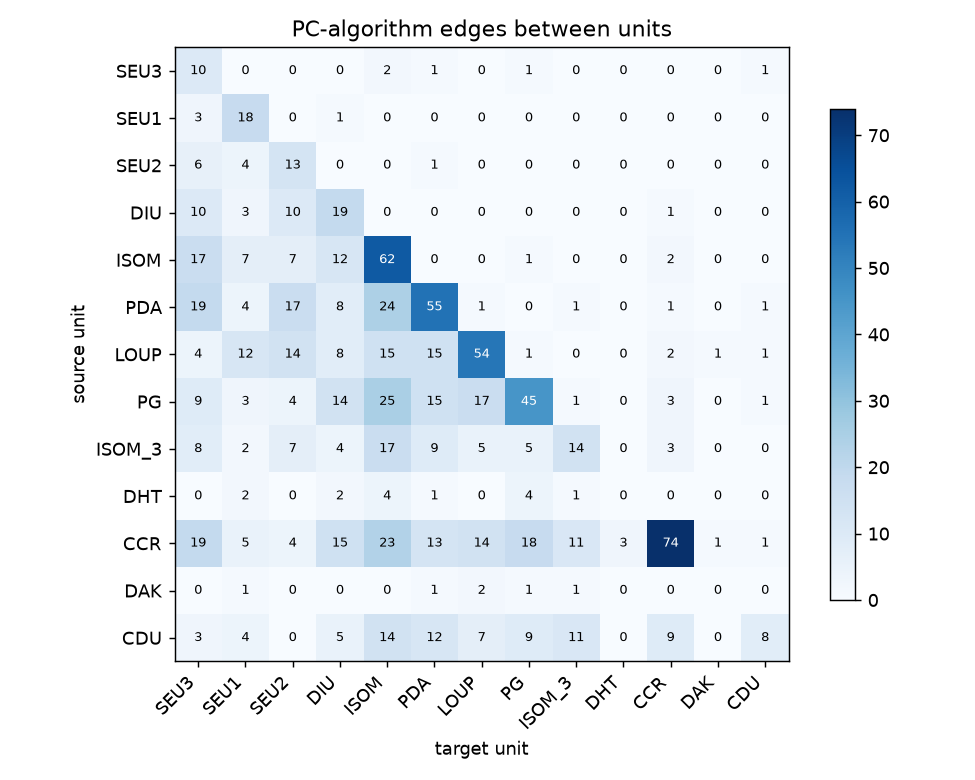

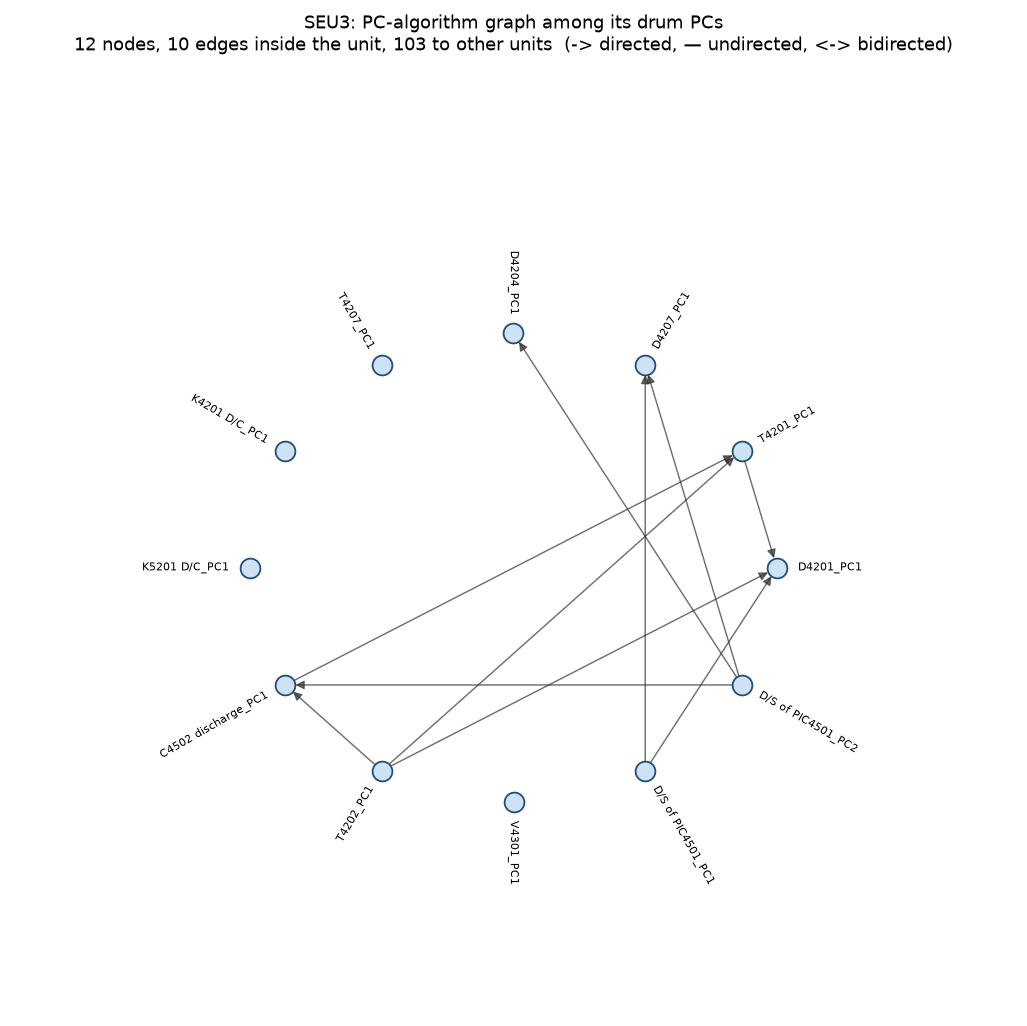

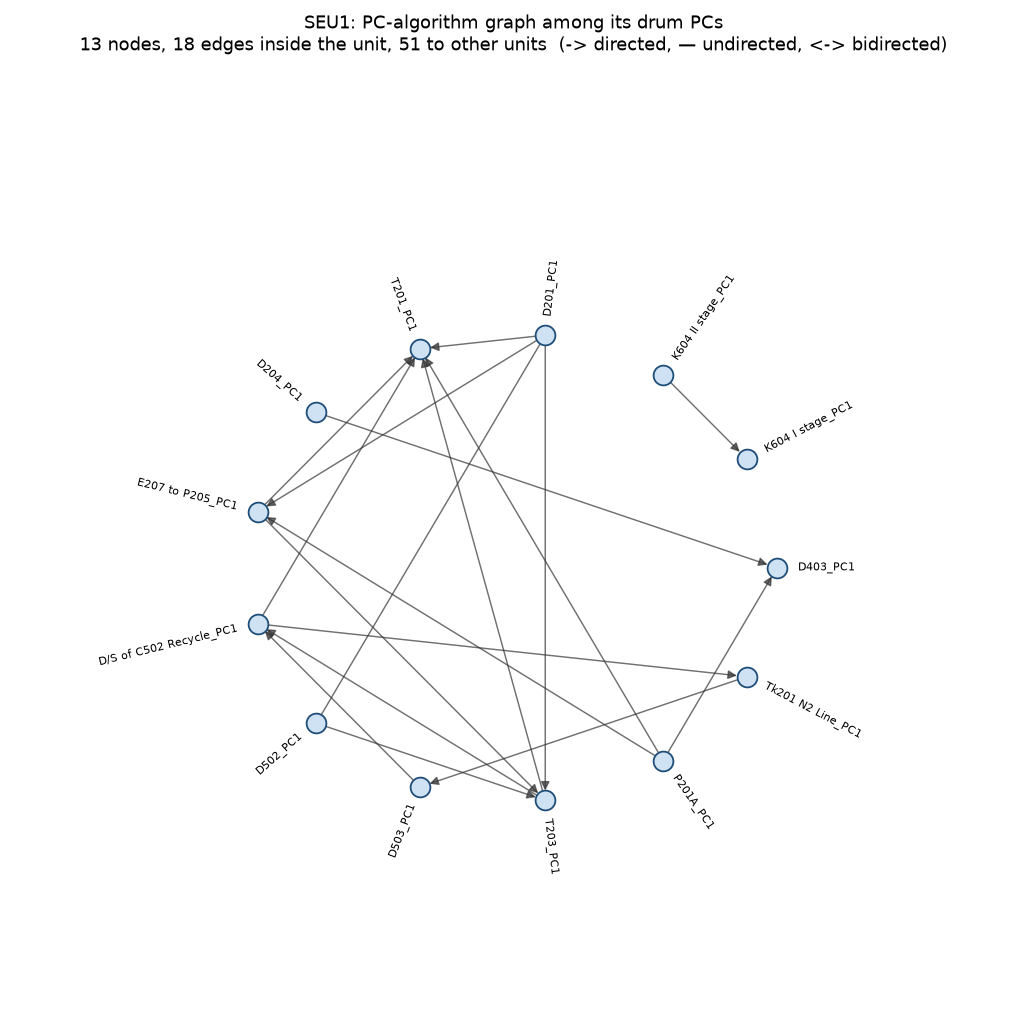

In [11]:
import textwrap

STYLE = {"->": dict(style="solid", arrows=True, arrowstyle="-|>"),
         "--": dict(style="solid", arrows=False),
         "<->": dict(style="dashed", arrows=True, arrowstyle="<|-|>")}


def draw_edges(ax, Gx, pos, edges, **style):
    """One draw call per edge type (one call per edge is slow for thousands of edges)."""
    by_type = {}
    for e in edges:
        by_type.setdefault(e["type"], []).append((e["source"], e["target"]))
    for t, el in by_type.items():
        st = STYLE.get(t, dict(style="dotted", arrows=False))
        kw = {k: v for k, v in st.items() if k != "style"}
        nx.draw_networkx_edges(Gx, pos, edgelist=el, ax=ax, style=st["style"], edge_color="#333333", **kw, **style)


def draw_graph(ax, g, title=None, font=8):
    nodes = g["nodes"]
    Gx = nx.DiGraph()
    Gx.add_nodes_from(nodes)
    pos = nx.circular_layout(Gx) if len(nodes) > 1 else {nodes[0]: np.zeros(2)}
    nx.draw_networkx_nodes(Gx, pos, ax=ax, node_color="#cfe2f3", edgecolors="#1f4e79", node_size=900)
    nx.draw_networkx_labels(Gx, pos, ax=ax, labels={n: "PC" + n.rsplit("_PC", 1)[1] for n in nodes},
                            font_size=font, font_weight="bold")
    under = {n: p + np.array([0, -0.32]) for n, p in pos.items()}          # full drum_PC# name below the node
    nx.draw_networkx_labels(Gx, under, ax=ax, labels={n: "\n".join(textwrap.wrap(n, 18)) for n in nodes},
                            font_size=font - 1, verticalalignment="top")
    draw_edges(ax, Gx, pos, g["edges"], node_size=900, width=1.6)
    ax.set_title(title or g["drum"], fontsize=font + 1)
    ax.set_xlim(-1.7, 1.7)                 # fixed frame: a 1-node graph has zero data range
    ax.set_ylim(-1.8, 1.4)
    ax.axis("off")


matplotlib.use("Agg")
t0 = time.time()
for d, g in GRAPHS.items():
    m = MODELS[d]
    folder = OUT_DIR / "graphs_png" / g["unit"]
    folder.mkdir(exist_ok=True)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    draw_graph(ax, g, f"{g['unit']} | {d}\n{len(g['edges'])} edge(s), {len(g['nodes'])} PC(s)")
    fig.tight_layout()
    fig.savefig(folder / f"{m['stem']}.png", dpi=120)
    plt.close(fig)

for u, g in UNIT_GRAPHS.items():                  # one summary figure per unit: its part of the one graph
    nodes = g["nodes"]
    if not nodes:
        continue
    Gx = nx.DiGraph()
    Gx.add_nodes_from(nodes)
    pos = nx.circular_layout(Gx) if len(nodes) > 1 else {nodes[0]: np.zeros(2)}
    size = max(8.0, 0.22 * len(nodes) + 4)
    fig, ax = plt.subplots(figsize=(size, size))
    nx.draw_networkx_nodes(Gx, pos, ax=ax, node_color="#cfe2f3", edgecolors="#1f4e79", node_size=120)
    draw_edges(ax, Gx, pos, g["edges"], node_size=120, width=0.8, alpha=0.7)
    for n, (x, y) in pos.items():                 # drum_PC# labels outside the circle
        ang = np.degrees(np.arctan2(y, x))
        flip = 90 < abs(ang)
        ax.text(1.08 * x, 1.08 * y, n, fontsize=6, rotation=ang + 180 if flip else ang,
                ha="right" if flip else "left", va="center", rotation_mode="anchor")
    ax.set_title(f"{u}: PC-algorithm graph among its drum PCs\n{len(nodes)} nodes, {len(g['edges'])} edges inside "
                 f"the unit, {len(g['edges_to_other_units'])} to other units  (-> directed, — undirected, <-> bidirected)",
                 fontsize=10, pad=40)
    ax.set_xlim(-1.9, 1.9)
    ax.set_ylim(-1.9, 1.9)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "graphs_png" / f"_summary_{u}.png", dpi=130, bbox_inches="tight")
    plt.close(fig)

# edges between units, one heat map
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(cross.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(cross.columns)), cross.columns, rotation=45, ha="right")
ax.set_yticks(range(len(cross.index)), cross.index)
for (i, j), v in np.ndenumerate(cross.to_numpy()):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=7,
            color="white" if v > cross.to_numpy().max() / 2 else "black")
ax.set_xlabel("target unit")
ax.set_ylabel("source unit")
ax.set_title("PC-algorithm edges between units")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(OUT_DIR / "graphs_png" / "_edges_unit_by_unit.png", dpi=130)
plt.close(fig)
print(f"graph figures written in {time.time() - t0:.0f} s")
display(Image(filename=str(OUT_DIR / "graphs_png" / "_edges_unit_by_unit.png")))
for u in [u for u, g in UNIT_GRAPHS.items() if g["nodes"]][:2]:
    display(Image(filename=str(OUT_DIR / "graphs_png" / f"_summary_{u}.png")))
STAGE_TIMES["5 graph figures"] = time.time() - t0


## Step 6 - Moving-Window T² and Individual T² (with Part A Audit)

### Part A Audit of Existing T² / PCA Code (Prior State)
1. **Moving window:** Previously **no** moving window was used in `drum_pca_pc.ipynb`. `drum_t2(m, X)` scored each observation row-by-row independently. (The reference pipeline `flare_pca_sfa_monitor_4windows_v2.ipynb` used an adaptive `NW = 2880`-sample window only for *model refitting*, while still scoring individual samples per instant.)
2. **Timestamps used:** `Xall = data` scored **all timestamps** (including flare and pre-flare rows), preserving `data.index`.
3. **Exact formulas:**
   - Standardised tags: `Z = (X - m["mu"]) / m["sd"]` (clipped if `USE_Z_CLIP`)
   - Individual T² (per PC *j*): `T2j = (Z @ m["P"] - m["mu_y"]) ** 2 / m["var_y"]`
   - Total T²: `T2 = T2j.sum(1)`
4. **PCA fitting scope:** **Yes**, PCA scaler (`mu`, `sd`) and model (`P`, `mu_y`, `var_y`, `lam`) were fitted strictly on `normal = data.loc[~removed]` (flare and pre-flare window removed), with `sd_long` only acting as a `0.1x` numerical floor.

### Moving-Window Convention Implemented
- Keep PCA scaler/model fitted on `normal` only; compute T² and individual T² on **all timestamps** (`data.index` preserved).
- **Trailing window (`T2_WINDOW_SIZE`, default 2):** compute per-sample standardised PC scores `Y = Z @ P`, average the PC scores over the trailing window `[t - W + 1, t]` (past data only, zero look-ahead), then apply the exact notebook formulas `T2j = (Y_win - mu_y)^2 / var_y` and `T2 = sum_j T2j`.
- The first `T2_WINDOW_SIZE - 1` rows and any window crossing a timestamp gap `> sampling_interval * MAX_GAP_FACTOR` are explicitly set to `NaN` without dropping the timestamp index.
- Alarm thresholds per drum are computed strictly from valid `normal` (`~removed`) moving-window T² values (`empirical` percentile or `ucl` F/chi² limit).


In [30]:
from scipy.stats import f as f_dist, chi2

# [TA] sfa + Model.statistics, used only to verify T2 == T2_slow + T2_fast --------
SFA_RCOND, SLOW_FRAC, MIN_SLOW, MIN_FAST = 1e-4, 0.2, 2, 2


def sfa(Y):
    mu_y = Y.mean(0)
    Yc = Y - mu_y
    lam, U = np.linalg.eigh(np.atleast_2d(np.cov(Yc, rowvar=False)))
    o = np.argsort(lam)[::-1]
    lam, U = lam[o], U[:, o]
    keep = lam > max(lam[0] * SFA_RCOND, EPS)
    Wh = U[:, keep] / np.sqrt(lam[keep])
    sp, R = np.linalg.eigh(np.atleast_2d(np.cov(np.diff(Yc @ Wh, axis=0), rowvar=False)))
    o = np.argsort(sp)
    return Wh @ R[:, o], np.clip(sp[o], EPS, None), mu_y


def ta_statistics(Z, P, W, mu_y, M):
    S = (Z @ P - mu_y) @ W
    return (S[:, :M] ** 2).sum(1), (S[:, M:] ** 2).sum(1)
# -------------------------------------------------------------------------------


def compute_gap_cross(index, window_size=T2_WINDOW_SIZE, max_gap_factor=MAX_GAP_FACTOR):
    """Detect timestamp gaps > sampling_interval * max_gap_factor and mark trailing windows crossing a gap."""
    dt = index.to_series().diff().dt.total_seconds().to_numpy()
    valid_dt = dt[1:][np.isfinite(dt[1:]) & (dt[1:] > 0)]
    sampling_sec = float(np.median(valid_dt)) if len(valid_dt) else 60.0
    gap_step = np.zeros(len(index), dtype=bool)
    gap_step[1:] = (~np.isfinite(dt[1:])) | (dt[1:] > sampling_sec * max_gap_factor)
    if window_size <= 1:
        return np.zeros(len(index), dtype=bool), sampling_sec, gap_step
    cross = pd.Series(gap_step.astype(np.int32)).rolling(window_size - 1, min_periods=1).sum().to_numpy() > 0
    return cross, sampling_sec, gap_step


def drum_t2(m, X, window_size=1, gap_cross=None, return_z_win=False):
    """Trailing moving-window T2 and individual T2 (one column per PC) for raw rows X.
    window_size=1 reproduces per-sample scoring; window_size>1 averages PC scores over the trailing window."""
    Z = (X - m["mu"]) / m["sd"]
    if USE_Z_CLIP:
        Z = np.clip(Z, -Z_CLIP, Z_CLIP)
    Y = Z @ m["P"]
    if window_size > 1:
        Y_win = np.array(pd.DataFrame(Y).rolling(window_size, min_periods=window_size).mean(), dtype=float)
        Y_win[:window_size - 1] = np.nan
        if gap_cross is not None:
            Y_win[gap_cross] = np.nan
        if return_z_win:
            Z_win = np.array(pd.DataFrame(Z).rolling(window_size, min_periods=window_size).mean(), dtype=float)
            Z_win[:window_size - 1] = np.nan
            if gap_cross is not None:
                Z_win[gap_cross] = np.nan
    else:
        Y_win = Y
        Z_win = Z
    T2j = (Y_win - m["mu_y"]) ** 2 / m["var_y"]
    t2 = T2j.sum(1)
    if return_z_win:
        return t2, T2j, Z_win
    return t2, T2j


def compute_t2_threshold(t2_normal, k, n_fit, method=T2_THRESHOLD_METHOD,
                         percentile=T2_THRESHOLD_PERCENTILE, ucl_dist=T2_UCL_DIST):
    """Compute per-drum alarm threshold from normal-operation T2 (empirical percentile or F/chi2 UCL)."""
    alpha = 1.0 - float(percentile) / 100.0
    if method == "empirical":
        vals = t2_normal[np.isfinite(t2_normal)]
        return float(np.percentile(vals, percentile)) if len(vals) else np.nan
    if method == "ucl":
        k = max(int(k), 1)
        if ucl_dist == "F":
            if n_fit <= k:
                return np.inf
            return float(k * (n_fit ** 2 - 1) / (n_fit * (n_fit - k)) * f_dist.ppf(1.0 - alpha, k, n_fit - k))
        if ucl_dist == "chi2":
            return float(chi2.ppf(1.0 - alpha, k))
        raise ValueError(f"Unknown T2_UCL_DIST: {ucl_dist!r}")
    raise ValueError(f"Unknown T2_THRESHOLD_METHOD: {method!r}")


# verification on the normal rows (single-sample W=1 equality check)
worst = 0.0
for d, m in MODELS.items():
    X = normal[m["cols"]].to_numpy(float)
    Z = (X - m["mu"]) / m["sd"]
    W, _, mu_y = sfa(Z @ m["P"])
    r = W.shape[1]
    lo = max(1, MIN_SLOW)
    M = int(np.clip(np.ceil(SLOW_FRAC * r), lo, min(max(lo, r - MIN_FAST), max(1, r - 1))))
    t_s, t_f = ta_statistics(Z, m["P"], W, mu_y, M)
    t2, _ = drum_t2(m, X, window_size=1)
    worst = max(worst, float(np.max(np.abs(t2 - (t_s + t_f)) / np.maximum(t2, 1))))
print(f"max relative difference |T2 - (T2_slow + T2_fast)| over all drums (W=1): {worst:.2e}")


max relative difference |T2 - (T2_slow + T2_fast)| over all drums (W=1): 1.59e-13


In [31]:
Xall = data
t0 = time.time()
GAP_CROSS, SAMPLING_SEC, GAP_STEP = compute_gap_cross(Xall.index, T2_WINDOW_SIZE, MAX_GAP_FACTOR)
print(f"Timeline: {len(Xall):,} rows | median step: {SAMPLING_SEC:.0f} s | "
      f"gap steps (>{SAMPLING_SEC * MAX_GAP_FACTOR:.0f} s): {int(GAP_STEP.sum())} | "
      f"gap-crossing windows: {int(GAP_CROSS.sum())} | T2_WINDOW_SIZE={T2_WINDOW_SIZE}")

DRUM_NAMES = list(MODELS.keys())
T2_MAT = np.full((len(Xall), len(DRUM_NAMES)), np.nan, dtype=T2_DTYPE)
THRESHOLDS = {}

t2_index = []
reuse = marker_ok(OUT_DIR / "t2", H_T2)
n_reused = 0
n_fit_normal = len(normal)

for idx_d, (d, m) in enumerate(MODELS.items()):
    folder = OUT_DIR / "t2" / m["unit"]
    folder.mkdir(exist_ok=True)
    f = folder / f"{m['stem']}.parquet"
    if reuse and f.exists():
        t2 = pd.read_parquet(f, columns=["T2"])["T2"].to_numpy(float)
        n_reused += 1
    else:
        t2, T2j = drum_t2(m, Xall[m["cols"]].to_numpy(float), window_size=T2_WINDOW_SIZE, gap_cross=GAP_CROSS)
        out = pd.DataFrame(T2j.astype(T2_DTYPE), index=Xall.index, columns=[f"T2_{n}" for n in m["nodes"]])
        out.insert(0, "T2", t2.astype(T2_DTYPE))
        out.to_parquet(f)
    T2_MAT[:, idx_d] = t2.astype(T2_DTYPE)

    t2_norm = t2.astype(T2_DTYPE).astype(float)[~removed]
    thr_emp = compute_t2_threshold(t2_norm, len(m["nodes"]), n_fit_normal, method="empirical",
                                   percentile=T2_THRESHOLD_PERCENTILE)
    thr_ucl = compute_t2_threshold(t2_norm, len(m["nodes"]), n_fit_normal, method="ucl",
                                   percentile=T2_THRESHOLD_PERCENTILE, ucl_dist=T2_UCL_DIST)
    thr = thr_emp if T2_THRESHOLD_METHOD == "empirical" else thr_ucl
    THRESHOLDS[d] = thr

    t2_index.append({
        "unit": m["unit"], "drum": d, "file": str(f.relative_to(OUT_DIR)),
        "n_PCs": len(m["nodes"]), "window_size": T2_WINDOW_SIZE,
        "n_nan": int(np.isnan(t2).sum()),
        "threshold": thr, "threshold_empirical": thr_emp, "threshold_ucl": thr_ucl,
        "T2_median_normal": float(np.nanmedian(t2_norm)),
        "T2_median_flare": float(np.nanmedian(t2[in_flare])) if in_flare.any() else np.nan,
        "T2_median_prewindow": float(np.nanmedian(t2[pre_only])) if pre_only.any() else np.nan,
    })

(OUT_DIR / "t2" / "_settings_hash.txt").write_text(H_T2)
t2_table = pd.DataFrame(t2_index)
t2_table.to_csv(OUT_DIR / "t2_index.csv", index=False)
print(f"T2 files for {len(t2_table)} drums ({n_reused} reused) in {time.time() - t0:.0f} s "
      f"({sum(f.stat().st_size for f in (OUT_DIR / 't2').rglob('*.parquet')) / 1e9:.2f} GB) | "
      f"threshold method: {T2_THRESHOLD_METHOD} (p={T2_THRESHOLD_PERCENTILE})")
display(t2_table.head(10).round(3))
STAGE_TIMES["6 T2 files"] = time.time() - t0


Timeline: 523,084 rows | median step: 60 s | gap steps (>120 s): 0 | gap-crossing windows: 0 | T2_WINDOW_SIZE=2
T2 files for 251 drums (251 reused) in 10 s (1.67 GB) | threshold method: empirical (p=99)


,unit,drum,file,n_PCs,window_size,n_nan,threshold,threshold_empirical,threshold_ucl,T2_median_normal,T2_median_flare,T2_median_prewindow
0,SEU3,D4201,t2\SEU3\SEU3__D4201.parquet,1,2,1,8.715,8.715,6.635,0.095,0.118,0.143
1,SEU3,T4201,t2\SEU3\SEU3__T4201.parquet,1,2,1,58.500,58.500,6.635,0.014,0.011,0.013
2,SEU3,D4207,t2\SEU3\SEU3__D4207.parquet,1,2,1,36.927,36.927,6.635,0.104,0.387,0.311
3,SEU3,D4204,t2\SEU3\SEU3__D4204.parquet,1,2,1,8.613,8.613,6.635,0.942,0.942,0.942
4,SEU3,D4208,t2\SEU3\SEU3__D4208.parquet,1,2,1,36.927,36.927,6.635,0.104,0.387,0.311
5,SEU3,T4207,t2\SEU3\SEU3__T4207.parquet,1,2,1,1.373,1.373,6.635,1.105,1.138,1.117
6,SEU3,K4201 D/C,t2\SEU3\SEU3__K4201_D_C.parquet,1,2,1,32.608,32.608,6.635,0.033,0.033,0.033
7,SEU3,K5201 D/C,t2\SEU3\SEU3__K5201_D_C.parquet,1,2,1,10.768,10.768,6.635,0.026,0.026,0.026
8,SEU3,C4502 discharge,t2\SEU3\SEU3__C4502_discharge.parquet,1,2,1,45.202,45.202,6.635,0.112,0.116,0.081
9,SEU3,D4502,t2\SEU3\SEU3__D4502.parquet,1,2,1,8.374,8.374,6.635,0.414,0.521,0.589


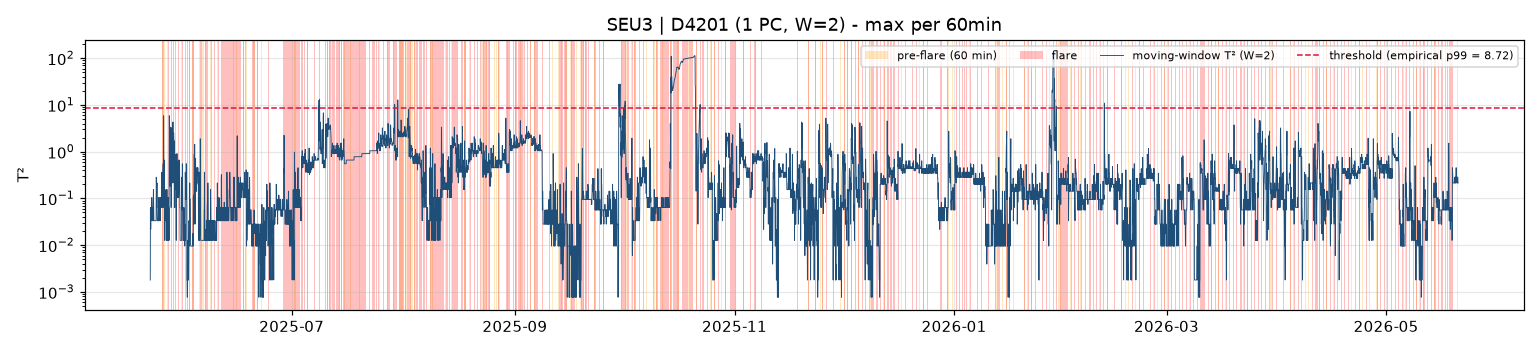

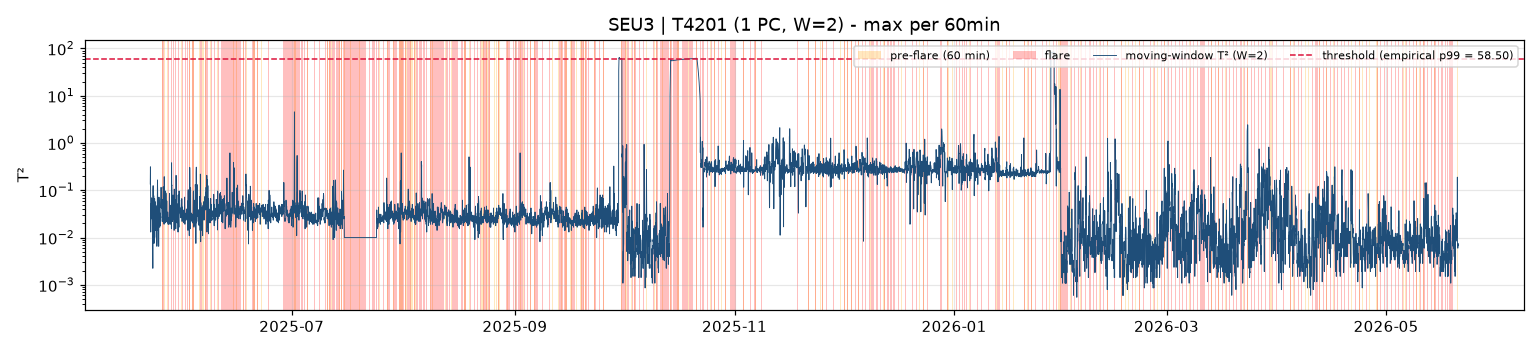

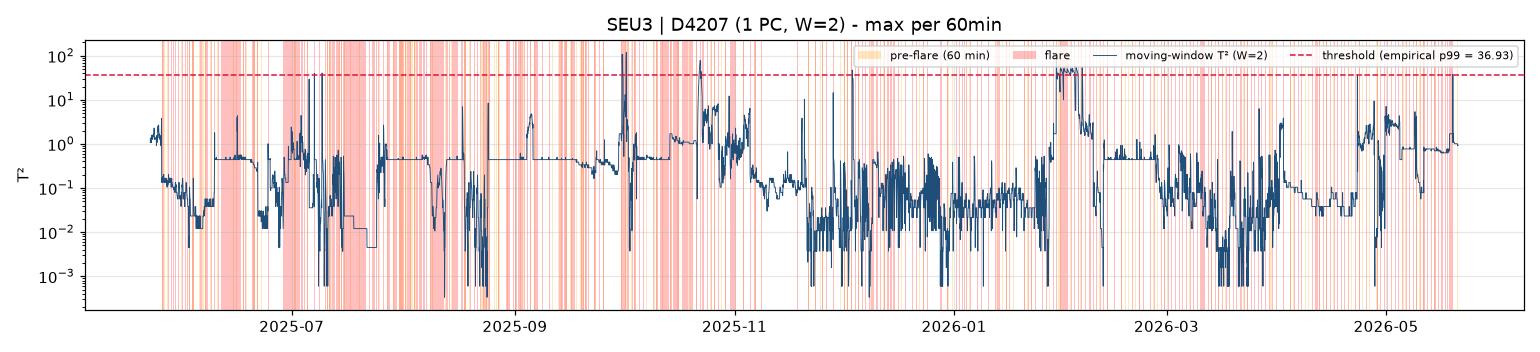

T2 plots: 0 written, 251 reused, in 0 s


In [32]:
# Moving-window T2 over time per drum (max per PLOT_RESAMPLE bin), threshold dashed, flare red, pre-flare orange
shade = pd.DataFrame({"flare": in_flare, "pre": pre_only}, index=data.index).resample(PLOT_RESAMPLE).max()
t0 = time.time()
reuse = marker_ok(OUT_DIR / "t2_plots", H_T2_PLOTS)
n_reused = 0
for i, r in enumerate(t2_table.itertuples()):
    folder = OUT_DIR / "t2_plots" / r.unit
    path = folder / f"{Path(r.file).stem}.png"
    if reuse and path.exists():
        n_reused += 1
        if i < N_EXAMPLE_PLOTS:
            display(Image(filename=str(path)))
        continue
    s = pd.Series(T2_MAT[:, i].astype(float), index=Xall.index).resample(PLOT_RESAMPLE).max()
    fig, ax = plt.subplots(figsize=(14, 3.2))
    tr = ax.get_xaxis_transform()
    ax.fill_between(shade.index, 0, 1, where=shade["pre"].to_numpy(), step="post", transform=tr,
                    color="orange", alpha=0.25, lw=0, label=f"pre-flare ({FLARE_PRE_WINDOW_MIN} min)")
    ax.fill_between(shade.index, 0, 1, where=shade["flare"].to_numpy(), step="post", transform=tr,
                    color="red", alpha=0.25, lw=0, label="flare")
    ax.plot(s.index, s.values, lw=0.6, color="#1f4e79", label=f"moving-window T² (W={T2_WINDOW_SIZE})")
    if np.isfinite(r.threshold) and r.threshold > 0:
        ax.axhline(r.threshold, color="crimson", ls="--", lw=1.0,
                   label=f"threshold ({T2_THRESHOLD_METHOD} p{T2_THRESHOLD_PERCENTILE} = {r.threshold:.2f})")
    ax.set_yscale("log")
    ax.set_ylabel("T²")
    ax.set_title(f"{r.unit} | {r.drum} ({r.n_PCs} PC, W={T2_WINDOW_SIZE}) - max per {PLOT_RESAMPLE}")
    ax.legend(loc="upper right", fontsize=7.5, ncol=4)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    folder.mkdir(exist_ok=True)
    fig.savefig(path, dpi=110)
    plt.close(fig)
    if i < N_EXAMPLE_PLOTS:
        display(Image(filename=str(path)))
(OUT_DIR / "t2_plots" / "_settings_hash.txt").write_text(H_T2_PLOTS)
print(f"T2 plots: {len(t2_table) - n_reused} written, {n_reused} reused, in {time.time() - t0:.0f} s")
STAGE_TIMES["6 T2 plots"] = time.time() - t0


## Step 7 - Flare Detection, Confusion Matrix & Sensitivity Analysis

### Definitions Used
- **Pre-flare window:** `[flare_start - FLARE_PRE_WINDOW_MIN, flare_start)` (excluding timestamps inside an earlier flare when `EXCLUDE_FLARE_FROM_PRE_WINDOW = True`, so ongoing flares do not count as pre-flare signals for subsequent flares).
- **Drum signal:** Moving-window T² exceeds the drum's normal-operation threshold for at least `MIN_EXCEED_SAMPLES` consecutive samples inside the pre-flare window (or, if `USE_MEAN_SHIFT_SIGNAL = True`, pre-flare T² mean is significantly higher than the preceding `BASELINE_WINDOW_MIN`-min normal baseline via one-sided Welch's *t*-test at `MEAN_SHIFT_ALPHA`).
- **TP (True Positive):** Flare event with at least `MIN_DRUMS_SIGNALING` drum(s) signaling in its pre-flare window (for per-unit: `>= 1` drum in the unit; for per-drum: that drum).
- **FN (False Negative):** Flare event with no qualifying signal in its pre-flare window.
- **FP (False Positive):** Alarm episodes on normal-operation timestamps outside every flare and every pre-flare window (`~removed`), where consecutive qualifying exceedance samples separated by `< ALARM_MERGE_MIN` non-alarm minutes are merged into one episode.
- **TN (True Negative):** Non-flare, non-pre-flare periods without alarms, counted in **units of non-overlapping windows of length `FLARE_PRE_WINDOW_MIN` (60 min)** inside contiguous normal-operation segments without timestamp gaps.


In [33]:
from scipy.stats import ttest_ind

t0 = time.time()
ts_all = Xall.index
ts_ns = ts_all.to_numpy()
step_min = SAMPLING_SEC / 60.0
eval_events = ev_in.sort_values("start").reset_index(drop=True)

# Precompute pre-flare window index arrays for every flare overlapping the process timeline
pre_slices = []
base_slices = []
for e in eval_events.itertuples(index=False):
    w_mask = (ts_all >= e.start - pd.Timedelta(minutes=FLARE_PRE_WINDOW_MIN)) & (ts_all < e.start)
    if EXCLUDE_FLARE_FROM_PRE_WINDOW:
        w_mask = w_mask & (~in_flare)
    pre_slices.append(np.flatnonzero(w_mask))
    b_start = e.start - pd.Timedelta(minutes=FLARE_PRE_WINDOW_MIN + BASELINE_WINDOW_MIN)
    b_end = e.start - pd.Timedelta(minutes=FLARE_PRE_WINDOW_MIN)
    b_mask = (ts_all >= b_start) & (ts_all < b_end) & (~removed)
    base_slices.append(np.flatnonzero(b_mask))

# Precompute contiguous non-overlapping TN windows of length FLARE_PRE_WINDOW_MIN inside (~removed & ~GAP_STEP)
win_samples = max(1, int(round(FLARE_PRE_WINDOW_MIN / step_min)))
tn_windows = []
norm_valid = (~removed) & (~GAP_STEP)
d_norm = np.diff(np.r_[0, norm_valid.astype(np.int8), 0])
for seg_s, seg_e in zip(np.flatnonzero(d_norm == 1), np.flatnonzero(d_norm == -1)):
    # Include the sample just before a gap_step? No: seg_s..seg_e are contiguous 1-min normal samples
    for start_i in range(seg_s, seg_e - win_samples + 1, win_samples):
        tn_windows.append((start_i, start_i + win_samples))
normal_days = float((~removed).sum() * step_min / 1440.0)


def filter_min_consecutive(mask, min_len):
    """Keep only True runs of length >= min_len."""
    if min_len <= 1:
        return mask
    out = np.zeros_like(mask, dtype=bool)
    d = np.diff(np.r_[0, mask.astype(np.int8), 0])
    for s, e in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)):
        if e - s >= min_len:
            out[s:e] = True
    return out


def first_run_confirm_pos(mask, min_len):
    """Return index within mask of confirmation sample (start + min_len - 1) of first run >= min_len, or None."""
    if not mask.any():
        return None
    d = np.diff(np.r_[0, mask.astype(np.int8), 0])
    for s, e in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)):
        if e - s >= min_len:
            return int(s + min_len - 1)
    return None


def merge_fp_episodes(alarm_mask, timestamps_ns, normal_mask, merge_min=ALARM_MERGE_MIN):
    """Merge normal-period alarms separated by < merge_min non-alarm minutes into episodes."""
    idx = np.flatnonzero(alarm_mask & normal_mask)
    if len(idx) == 0:
        return []
    episodes = []
    ep_s = ep_e = idx[0]
    for cur in idx[1:]:
        if not normal_mask[ep_e:cur + 1].all() or GAP_STEP[ep_e + 1:cur + 1].any():
            episodes.append((ep_s, ep_e))
            ep_s = ep_e = cur
            continue
        gap_between_min = (timestamps_ns[cur] - timestamps_ns[ep_e]) / np.timedelta64(1, "m") - step_min
        if cur == ep_e + 1 or gap_between_min < merge_min:
            ep_e = cur
        else:
            episodes.append((ep_s, ep_e))
            ep_s = ep_e = cur
    episodes.append((ep_s, ep_e))
    return episodes


def compute_cm_metrics(tp, fn, fp, tn, lead_times):
    prec = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    rec = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    f1 = (2 * prec * rec / (prec + rec)) if (np.isfinite(prec) and np.isfinite(rec) and (prec + rec) > 0) else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    acc = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else np.nan
    lt = np.asarray(lead_times, dtype=float)
    lt = lt[np.isfinite(lt)]
    return {
        "n_flares": int(tp + fn), "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "precision": prec, "recall": rec, "f1": f1,
        "false_alarm_rate": fpr, "specificity": spec, "accuracy": acc,
        "fp_per_day": fp / max(normal_days, EPS),
        "mean_lead_min": float(np.mean(lt)) if len(lt) else np.nan,
        "median_lead_min": float(np.median(lt)) if len(lt) else np.nan,
    }


def evaluate_detector(drum_hit_mat, drum_lead_mat, alarm_mask_bool, min_drums=1, return_details=False):
    """Score flare TP/FN, FP episodes, and TN windows given per-drum flare hits and boolean alarm mask."""
    n_sig = drum_hit_mat.sum(axis=1)
    detected = n_sig >= min_drums
    leads = np.full(len(eval_events), np.nan)
    for fi in np.flatnonzero(detected):
        # earliest confirmation across signaling drums (when min_drums == 1, max lead_min; in general, min_drums-th earliest)
        dl = drum_lead_mat[fi, drum_hit_mat[fi]]
        dl = dl[np.isfinite(dl)]
        if len(dl) >= min_drums:
            leads[fi] = float(np.sort(dl)[::-1][min_drums - 1])
    tp = int(detected.sum())
    fn = int(len(eval_events) - tp)
    eps = merge_fp_episodes(alarm_mask_bool, ts_ns, ~removed, ALARM_MERGE_MIN)
    fp = len(eps)
    tn = sum(1 for a, b in tn_windows if not alarm_mask_bool[a:b].any())
    metrics = compute_cm_metrics(tp, fn, fp, tn, leads[detected])
    if return_details:
        return metrics, detected, leads, n_sig, eps
    return metrics


def detect_drum_flares(t2_vec, thr):
    """Return per-flare boolean hit, lead_time_min, and qualifying sample-level alarm mask."""
    exc_raw = np.isfinite(t2_vec) & (t2_vec > thr)
    alarm_q = filter_min_consecutive(exc_raw, MIN_EXCEED_SAMPLES)
    hits = np.zeros(len(eval_events), dtype=bool)
    leads = np.full(len(eval_events), np.nan)
    for fi, pidx in enumerate(pre_slices):
        if len(pidx) == 0:
            continue
        if USE_MEAN_SHIFT_SIGNAL:
            pv = t2_vec[pidx]
            bv = t2_vec[base_slices[fi]]
            pv = pv[np.isfinite(pv)]
            bv = bv[np.isfinite(bv)]
            if len(pv) >= 2 and len(bv) >= 2 and pv.mean() > bv.mean():
                _, pval = ttest_ind(pv, bv, equal_var=False, alternative="greater")
                if np.isfinite(pval) and pval < MEAN_SHIFT_ALPHA:
                    hits[fi] = True
                    pos = first_run_confirm_pos(exc_raw[pidx], MIN_EXCEED_SAMPLES)
                    leads[fi] = float((eval_events.start.iloc[fi] - ts_all[pidx[pos if pos is not None else 0]]).total_seconds() / 60.0)
        else:
            pos = first_run_confirm_pos(exc_raw[pidx], MIN_EXCEED_SAMPLES)
            if pos is not None:
                hits[fi] = True
                leads[fi] = float((eval_events.start.iloc[fi] - ts_all[pidx[pos]]).total_seconds() / 60.0)
    return hits, leads, alarm_q


# ---- Compute per-drum, per-unit, and plant-level detection & confusion matrices ----
print("Confusion-matrix definitions:")
print(f"  TP: flare with >= {MIN_DRUMS_SIGNALING} drum signaling in [{FLARE_PRE_WINDOW_MIN} min, 0) pre-flare window")
print(f"  FN: flare with no signal in its pre-flare window")
print(f"  FP: alarm episodes outside flares & pre-flare windows (consecutive alarms separated by < {ALARM_MERGE_MIN} min merged)")
print(f"  TN: non-flare/non-pre-flare periods without alarms, in non-overlapping {FLARE_PRE_WINDOW_MIN}-min windows ({len(tn_windows):,} windows total)")

N_EV = len(eval_events)
N_DRUMS = len(DRUM_NAMES)
DRUM_HITS = np.zeros((N_EV, N_DRUMS), dtype=bool)
DRUM_LEADS = np.full((N_EV, N_DRUMS), np.nan)
DRUM_ALARMS = np.zeros((len(Xall), N_DRUMS), dtype=bool)

drum_cm_rows = []
for di, d in enumerate(DRUM_NAMES):
    hits, leads, alarm_q = detect_drum_flares(T2_MAT[:, di].astype(float), THRESHOLDS[d])
    DRUM_HITS[:, di] = hits
    DRUM_LEADS[:, di] = leads
    DRUM_ALARMS[:, di] = alarm_q
    m_d = evaluate_detector(hits[:, None], leads[:, None], alarm_q, min_drums=1)
    drum_cm_rows.append({"unit": MODELS[d]["unit"], "drum": d, "threshold": THRESHOLDS[d], **m_d})

drum_cm_df = pd.DataFrame(drum_cm_rows).sort_values(["f1", "recall"], ascending=False).reset_index(drop=True)
drum_cm_df.to_csv(OUT_DIR / "confusion_matrix_per_drum.csv", index=False)

unit_cm_rows = []
for u in unit_drums:
    u_idx = [i for i, d in enumerate(DRUM_NAMES) if MODELS[d]["unit"] == u]
    if not u_idx:
        continue
    u_alarm = DRUM_ALARMS[:, u_idx].any(axis=1)
    m_u = evaluate_detector(DRUM_HITS[:, u_idx], DRUM_LEADS[:, u_idx], u_alarm, min_drums=1)
    unit_cm_rows.append({"unit": u, "n_drums": len(u_idx), **m_u})

unit_cm_df = pd.DataFrame(unit_cm_rows).sort_values(["f1", "recall"], ascending=False).reset_index(drop=True)
unit_cm_df.to_csv(OUT_DIR / "confusion_matrix_per_unit.csv", index=False)

plant_alarm = DRUM_ALARMS.sum(axis=1) >= MIN_DRUMS_SIGNALING
plant_m, plant_det, plant_leads, plant_n_sig, fp_episodes = evaluate_detector(
    DRUM_HITS, DRUM_LEADS, plant_alarm, min_drums=MIN_DRUMS_SIGNALING, return_details=True
)
overall_cm_df = pd.DataFrame([{"scope": "PLANT_OVERALL", "window_size": T2_WINDOW_SIZE,
                               "threshold_method": T2_THRESHOLD_METHOD, "percentile": T2_THRESHOLD_PERCENTILE,
                               "min_drums_signaling": MIN_DRUMS_SIGNALING, **plant_m}])
overall_cm_df.to_csv(OUT_DIR / "confusion_matrix_overall.csv", index=False)

flare_det_df = eval_events.copy()
flare_det_df["detected"] = plant_det
flare_det_df["outcome"] = np.where(plant_det, "TP", "FN")
flare_det_df["n_drums_signaling"] = plant_n_sig
flare_det_df["lead_time_min"] = plant_leads
flare_det_df.to_csv(OUT_DIR / "flare_detection_events.csv", index=False)

fp_df = pd.DataFrame([{"episode_id": i + 1, "start": ts_all[s], "end": ts_all[e],
                       "duration_min": (e - s + 1) * step_min,
                       "n_alarm_samples": int(plant_alarm[s:e + 1].sum()),
                       "peak_drums_alarming": int(DRUM_ALARMS[s:e + 1].sum(axis=1).max())}
                      for i, (s, e) in enumerate(fp_episodes)])
fp_df.to_csv(OUT_DIR / "false_alarm_episodes.csv", index=False)

print("\nPlant-level confusion matrix & metrics:")
display(overall_cm_df.round(4))
print("\nPer-unit confusion matrix & metrics:")
display(unit_cm_df.round(4))
print("\nTop 15 drums by F1:")
display(drum_cm_df.head(15).round(4))
STAGE_TIMES["7 detection & CM"] = time.time() - t0


Confusion-matrix definitions:
  TP: flare with >= 1 drum signaling in [60 min, 0) pre-flare window
  FN: flare with no signal in its pre-flare window
  FP: alarm episodes outside flares & pre-flare windows (consecutive alarms separated by < 5 min merged)
  TN: non-flare/non-pre-flare periods without alarms, in non-overlapping 60-min windows (4,890 windows total)

Plant-level confusion matrix & metrics:


,scope,window_size,threshold_method,percentile,min_drums_signaling,n_flares,TP,FN,FP,TN,precision,recall,f1,false_alarm_rate,specificity,accuracy,fp_per_day,mean_lead_min,median_lead_min
0,PLANT_OVERALL,2,empirical,99,1,1294,1068,226,2710,1037,0.2827,0.8253,0.4211,0.7232,0.2768,0.4176,12.5706,41.4457,55.0



Per-unit confusion matrix & metrics:


,unit,n_drums,n_flares,TP,FN,FP,TN,precision,recall,f1,false_alarm_rate,specificity,accuracy,fp_per_day,mean_lead_min,median_lead_min
0,CCR,51,1294,455,839,624,3852,0.4217,0.3516,0.3835,0.1394,0.8606,0.7464,2.8945,36.9736,43.0
1,LOUP,33,1294,372,922,485,3906,0.4341,0.2875,0.3459,0.1105,0.8895,0.7525,2.2497,36.0591,39.5
2,SEU3,16,1294,310,984,572,4231,0.3515,0.2396,0.2849,0.1191,0.8809,0.7448,2.6533,35.3000,38.0
3,PG,16,1294,273,1021,635,4160,0.3007,0.2110,0.2480,0.1324,0.8676,0.7280,2.9455,37.7143,40.0
4,SEU2,13,1294,217,1077,488,4381,0.3078,0.1677,0.2171,0.1002,0.8998,0.7461,2.2636,34.2120,34.0
5,ISOM,29,1294,384,910,2081,3337,0.1558,0.2968,0.2043,0.3841,0.6159,0.5544,9.6529,39.4036,48.0
6,DIU,12,1294,171,1123,301,4346,0.3623,0.1321,0.1937,0.0648,0.9352,0.7603,1.3962,38.0351,45.0
7,PDA,36,1294,261,1033,1145,3849,0.1856,0.2017,0.1933,0.2293,0.7707,0.6536,5.3112,38.3985,45.0
8,ISOM_3,14,1294,172,1122,447,4304,0.2779,0.1329,0.1798,0.0941,0.9059,0.7404,2.0735,35.6628,37.0
9,CDU,11,1294,110,1184,249,4399,0.3064,0.0850,0.1331,0.0536,0.9464,0.7588,1.1550,37.9273,47.0



Top 15 drums by F1:


,unit,drum,threshold,n_flares,TP,FN,FP,TN,precision,recall,f1,false_alarm_rate,specificity,accuracy,fp_per_day,mean_lead_min,median_lead_min
0,CCR,Chiller Condenser E4091B(N),9.7811,1294,187,1107,73,4815,0.7192,0.1445,0.2407,0.0149,0.9851,0.8091,0.3386,32.3102,30.0
1,CCR,Chiller Condenser E4091A(N),10.3934,1294,176,1118,97,4804,0.6447,0.1360,0.2246,0.0198,0.9802,0.8039,0.4499,31.7386,29.5
2,CCR,Chiller Reciever D4092(R),11.2358,1294,165,1129,74,4817,0.6904,0.1275,0.2153,0.0151,0.9849,0.8055,0.3433,31.9030,28.0
3,CCR,Chiller Surge Drum D4093(R),8.7026,1294,124,1170,56,4822,0.6889,0.0958,0.1682,0.0115,0.9885,0.8014,0.2598,35.0161,35.0
4,LOUP,Nitrogen tanker header,6.9033,1294,105,1189,43,4820,0.7095,0.0811,0.1456,0.0088,0.9912,0.7999,0.1995,26.5905,21.0
5,PG,FUEL GAS KNOCKOUT DRUM,9.6540,1294,105,1189,162,4752,0.3933,0.0811,0.1345,0.0330,0.9670,0.7824,0.7515,30.4476,28.0
6,ISOM,FUEL GAS KNOCKOUT DRUM ( 103-D-3001 ),9.5628,1294,86,1208,184,4725,0.3185,0.0665,0.1100,0.0375,0.9625,0.7756,0.8535,28.3837,27.5
7,LOUP,99D07A,6.7877,1294,77,1217,41,4822,0.6525,0.0595,0.1091,0.0084,0.9916,0.7957,0.1902,28.7013,20.0
8,SEU3,D4204,8.6127,1294,77,1217,45,4851,0.6311,0.0595,0.1088,0.0092,0.9908,0.7961,0.2087,32.3117,34.0
9,LOUP,99D12,6.7836,1294,76,1218,44,4822,0.6333,0.0587,0.1075,0.0090,0.9910,0.7951,0.2041,29.5789,24.5


In [34]:
# ---- Sensitivity analysis over thresholds and window sizes ----
t0 = time.time()
W_LIST = list(SENSITIVITY_WINDOWS)
P_LIST = list(SENSITIVITY_PERCENTILES)
n_w, n_p = len(W_LIST), len(P_LIST)

# Accumulate per-(W, P) plant alarm masks and per-flare drum hit / lead counts in one pass per drum
sens_hits = np.zeros((n_w, n_p, N_EV, N_DRUMS), dtype=bool)
sens_leads = np.full((n_w, n_p, N_EV, N_DRUMS), np.nan, dtype=np.float32)
sens_alarm_counts = np.zeros((n_w, n_p, len(Xall)), dtype=np.uint16)

gap_cross_by_w = {W: compute_gap_cross(Xall.index, W, MAX_GAP_FACTOR)[0] for W in W_LIST}
raw_norm = ~removed

for di, d in enumerate(DRUM_NAMES):
    m = MODELS[d]
    X_d = Xall[m["cols"]].to_numpy(float)
    Z_d = (X_d - m["mu"]) / m["sd"]
    if USE_Z_CLIP:
        Z_d = np.clip(Z_d, -Z_CLIP, Z_CLIP)
    Y_d = Z_d @ m["P"]
    for wi, W in enumerate(W_LIST):
        if W > 1:
            Yw = pd.DataFrame(Y_d).rolling(W, min_periods=W).mean().to_numpy(float, copy = True)
            Yw[:W - 1] = np.nan
            Yw[gap_cross_by_w[W]] = np.nan
        else:
            Yw = Y_d
        t2_w = (((Yw - m["mu_y"]) ** 2) / m["var_y"]).sum(1)
        t2_w = t2_w.astype(T2_DTYPE).astype(float)
        t2_norm_vals = t2_w[raw_norm]
        t2_norm_vals = t2_norm_vals[np.isfinite(t2_norm_vals)]
        for pi, pct in enumerate(P_LIST):
            thr = compute_t2_threshold(t2_norm_vals, len(m["nodes"]), n_fit_normal,
                                       method=T2_THRESHOLD_METHOD, percentile=pct, ucl_dist=T2_UCL_DIST)
            hits, leads, alarm_q = detect_drum_flares(t2_w, thr)
            sens_hits[wi, pi, :, di] = hits
            sens_leads[wi, pi, :, di] = leads
            sens_alarm_counts[wi, pi] += alarm_q.astype(np.uint16)

sens_rows = []
for wi, W in enumerate(W_LIST):
    for pi, pct in enumerate(P_LIST):
        alarm_p = sens_alarm_counts[wi, pi] >= MIN_DRUMS_SIGNALING
        m_wp = evaluate_detector(sens_hits[wi, pi], sens_leads[wi, pi], alarm_p, min_drums=MIN_DRUMS_SIGNALING)
        sens_rows.append({"window_size": W, "percentile": pct, "threshold_method": T2_THRESHOLD_METHOD, **m_wp})

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv(OUT_DIR / "sensitivity_analysis.csv", index=False)

# Consistency check against main run if (T2_WINDOW_SIZE, T2_THRESHOLD_PERCENTILE) is in grid
match = sens_df[(sens_df.window_size == T2_WINDOW_SIZE) & (sens_df.percentile == T2_THRESHOLD_PERCENTILE)]
if len(match):
    r0 = match.iloc[0]
    assert int(r0.TP) == plant_m["TP"] and int(r0.FP) == plant_m["FP"] and int(r0.TN) == plant_m["TN"], \
        f"Sensitivity mismatch: {r0.to_dict()} vs {plant_m}"

print(f"Sensitivity analysis ({len(sens_df)} configs) completed in {time.time() - t0:.1f} s:")
display(sens_df.round(4))
STAGE_TIMES["7b sensitivity"] = time.time() - t0


Sensitivity analysis (16 configs) completed in 113.1 s:


,window_size,percentile,threshold_method,n_flares,TP,FN,FP,TN,precision,recall,f1,false_alarm_rate,specificity,accuracy,fp_per_day,mean_lead_min,median_lead_min
0,1,95.0,empirical,1294,1294,0,747,2,0.6340,1.0000,0.7760,0.9973,0.0027,0.6344,3.4650,44.3462,60.0
1,1,97.5,empirical,1294,1269,25,1557,118,0.4490,0.9807,0.6160,0.9296,0.0704,0.4672,7.2223,43.6564,60.0
2,1,99.0,empirical,1294,1066,228,2778,1023,0.2773,0.8238,0.4149,0.7309,0.2691,0.4100,12.8860,41.4625,55.0
3,1,99.5,empirical,1294,881,413,2752,1878,0.2425,0.6808,0.3576,0.5944,0.4056,0.4657,12.7654,39.3893,49.0
4,2,95.0,empirical,1294,1294,0,744,2,0.6349,1.0000,0.7767,0.9973,0.0027,0.6353,3.4511,44.3277,60.0
5,2,97.5,empirical,1294,1269,25,1529,127,0.4535,0.9807,0.6202,0.9233,0.0767,0.4732,7.0924,43.6596,60.0
6,2,99.0,empirical,1294,1068,226,2710,1037,0.2827,0.8253,0.4211,0.7232,0.2768,0.4176,12.5706,41.4457,55.0
7,2,99.5,empirical,1294,883,411,2647,1898,0.2501,0.6824,0.3661,0.5824,0.4176,0.4763,12.2784,39.2695,48.0
8,3,95.0,empirical,1294,1294,0,737,4,0.6371,1.0000,0.7783,0.9946,0.0054,0.6378,3.4186,44.3269,60.0
9,3,97.5,empirical,1294,1268,26,1471,136,0.4629,0.9799,0.6288,0.9154,0.0846,0.4840,6.8234,43.6254,60.0


## Step 8 - Root-Cause Ranking (Top 3 Drums & Top 3 Tags per Flare)

For every flare (`TP` and `FN`), drums are ranked by `max(T2 / threshold)` (tie-broken by `mean(T2 / threshold)`) in the pre-flare window.
Within each top-3 drum, the notebook's individual PC-level `T2j` is mapped back to active tags via each tag's absolute projection share `|Z_win * P| / sum(|Z_win * P|)` per PC (non-negative and summing exactly to total `T2`).


In [35]:
t0 = time.time()
thr_vec = np.array([THRESHOLDS[d] for d in DRUM_NAMES], dtype=float)
norm_t2_mat = T2_MAT.astype(float) / thr_vec[None, :]


def drum_top_tags_in_window(d, pidx, top_k=TOP_K_TAGS):
    """Rank active tags inside drum d over pre-flare indices pidx using individual T2 contributions."""
    m = MODELS[d]
    lo = max(0, int(pidx[0]) - (T2_WINDOW_SIZE - 1))
    hi = int(pidx[-1]) + 1
    X_sub = Xall[m["cols"]].iloc[lo:hi].to_numpy(float)
    g_sub = GAP_CROSS[lo:hi]
    _, T2j_sub, Z_win_sub = drum_t2(m, X_sub, window_size=T2_WINDOW_SIZE, gap_cross=g_sub, return_z_win=True)
    rel = pidx - lo
    T2j_w = T2j_sub[rel]
    Z_w = Z_win_sub[rel]
    valid = np.isfinite(T2j_w).all(axis=1) & np.isfinite(Z_w).all(axis=1)
    if not valid.any():
        return [{"tag": c.split("::", 1)[-1], "full_tag": c, "contrib_t2": np.nan, "contrib_pct": np.nan}
                for c in m["cols"][:top_k]]
    T2j_v = T2j_w[valid]
    Z_v = Z_w[valid]
    P = m["P"]
    w = np.abs(Z_v[:, :, None] * P[None, :, :])
    w_sum = w.sum(axis=1, keepdims=True)
    share = np.where(w_sum > EPS, w / np.maximum(w_sum, EPS), P[None, :, :] ** 2)
    tag_t2 = (T2j_v[:, None, :] * share).sum(axis=2).mean(axis=0)
    tot = max(float(tag_t2.sum()), EPS)
    order = np.argsort(-tag_t2)
    return [
        {
            "tag": m["cols"][ti].split("::", 1)[-1],
            "full_tag": m["cols"][ti],
            "contrib_t2": float(tag_t2[ti]),
            "contrib_pct": float(100.0 * tag_t2[ti] / tot),
        }
        for ti in order[:top_k]
    ]


rc_csv_rows = []
rc_json_events = []
for fi, e in enumerate(eval_events.itertuples(index=False)):
    pidx = pre_slices[fi]
    if len(pidx):
        sub = norm_t2_mat[pidx]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            max_scores = np.nanmax(sub, axis=0)
            mean_scores = np.nanmean(sub, axis=0)
    else:
        max_scores = np.full(N_DRUMS, np.nan)
        mean_scores = np.full(N_DRUMS, np.nan)

    key_max = np.where(np.isfinite(max_scores), max_scores, -1.0)
    key_mean = np.where(np.isfinite(mean_scores), mean_scores, -1.0)
    top_idx = sorted(range(N_DRUMS), key=lambda j: (key_max[j], key_mean[j]), reverse=True)[:TOP_K_DRUMS]

    top_drums_json = []
    for rank, di in enumerate(top_idx, start=1):
        d = DRUM_NAMES[di]
        u = MODELS[d]["unit"]
        d_score = float(max_scores[di]) if np.isfinite(max_scores[di]) else np.nan
        d_mean = float(mean_scores[di]) if np.isfinite(mean_scores[di]) else np.nan
        d_lead = float(DRUM_LEADS[fi, di]) if np.isfinite(DRUM_LEADS[fi, di]) else np.nan
        tags_info = drum_top_tags_in_window(d, pidx, TOP_K_TAGS) if len(pidx) else []
        top_tags_str = "; ".join(f"{t['tag']} ({t['contrib_pct']:.1f}%)" for t in tags_info)

        rc_csv_rows.append({
            "flare_id": int(e.event_id),
            "flare_start": str(e.start),
            "unit": u,
            "rank": rank,
            "drum": d,
            "drum_score": round(d_score, 4) if np.isfinite(d_score) else np.nan,
            "top_tags": top_tags_str,
            "lead_time_min": round(d_lead, 1) if np.isfinite(d_lead) else np.nan,
        })
        top_drums_json.append({
            "rank": rank,
            "unit": u,
            "drum": d,
            "drum_max_norm_t2": None if not np.isfinite(d_score) else round(d_score, 4),
            "drum_mean_norm_t2": None if not np.isfinite(d_mean) else round(d_mean, 4),
            "drum_signaled": bool(DRUM_HITS[fi, di]),
            "lead_time_min": None if not np.isfinite(d_lead) else round(d_lead, 1),
            "top_tags": tags_info,
        })

    rc_json_events.append({
        "flare_id": int(e.event_id),
        "flare_start": str(e.start),
        "flare_end": str(e.end),
        "duration_min": float(e.duration_min),
        "peak_flow": float(e.peak_flow),
        "detected": bool(plant_det[fi]),
        "outcome": "TP" if plant_det[fi] else "FN",
        "plant_lead_time_min": None if not np.isfinite(plant_leads[fi]) else round(float(plant_leads[fi]), 1),
        "n_drums_signaling": int(plant_n_sig[fi]),
        "top_drums": top_drums_json,
    })

rc_df = pd.DataFrame(rc_csv_rows, columns=["flare_id", "flare_start", "unit", "rank", "drum", "drum_score", "top_tags", "lead_time_min"])
rc_df.to_csv(OUT_DIR / "root_causes.csv", index=False)
(OUT_DIR / "root_causes.json").write_text(json.dumps(rc_json_events, indent=2), encoding="utf-8")

print(f"Root causes saved for {len(eval_events)} flares ({len(rc_df)} rows) in {time.time() - t0:.1f} s")
display(rc_df.head(15))
STAGE_TIMES["8 root causes"] = time.time() - t0


Root causes saved for 1294 flares (3882 rows) in 8.9 s


,flare_id,flare_start,unit,rank,drum,drum_score,top_tags,lead_time_min
0,1,2025-05-23 12:31:00,LOUP,1,99C01A,11.3454,99TI1320.DACA.PV (90.9%); 99TI1407.DACA.PV (9.1%),60.0
1,1,2025-05-23 12:31:00,LOUP,2,99C01B,11.2249,99TI1515.DACA.PV (93.6%); 99PC1527.DACA.PV (5....,60.0
2,1,2025-05-23 12:31:00,LOUP,3,99E13,10.9424,99TI4107.DACA.PV (100.0%),60.0
3,2,2025-05-25 22:42:00,ISOM,1,103-E-2004 tube side inlet (MP Steam),2.2495,103PI8208N.pv (95.6%); 103TI8208N.pv (4.4%),21.0
4,2,2025-05-25 22:42:00,SEU1,2,K604 I stage,1.9845,K604BTI1.PV (100.0%),60.0
5,2,2025-05-25 22:42:00,PG,3,GASOLINE SPLITTER,1.3428,105PI1518AN.PV (59.9%); 105TI1602.DACA.PV (40.1%),17.0
6,3,2025-05-26 01:43:00,DHT,1,T-2001 NAPHTHA STABILIZER,11.9427,700TI3932N (100.0%),46.0
7,3,2025-05-26 01:43:00,ISOM_3,2,19T4 O/H Line (caustic Tower) LPG Trtg,1.4579,19pt102.pv (100.0%),45.0
8,3,2025-05-26 01:43:00,ISOM_3,3,19D3 O/H Line (amine settler) LPG Trtg,1.4579,19pt102.pv (100.0%),45.0
9,4,2025-05-26 03:42:00,ISOM,1,DRYERS REGENERANT DEGASSER ( 103-D-2015 ),3.4480,103TI7102.daca.pv (100.0%),60.0


## Step 9 - Diagnostic Plots (Flare Zoom-Ins & Top Root-Cause Drums)

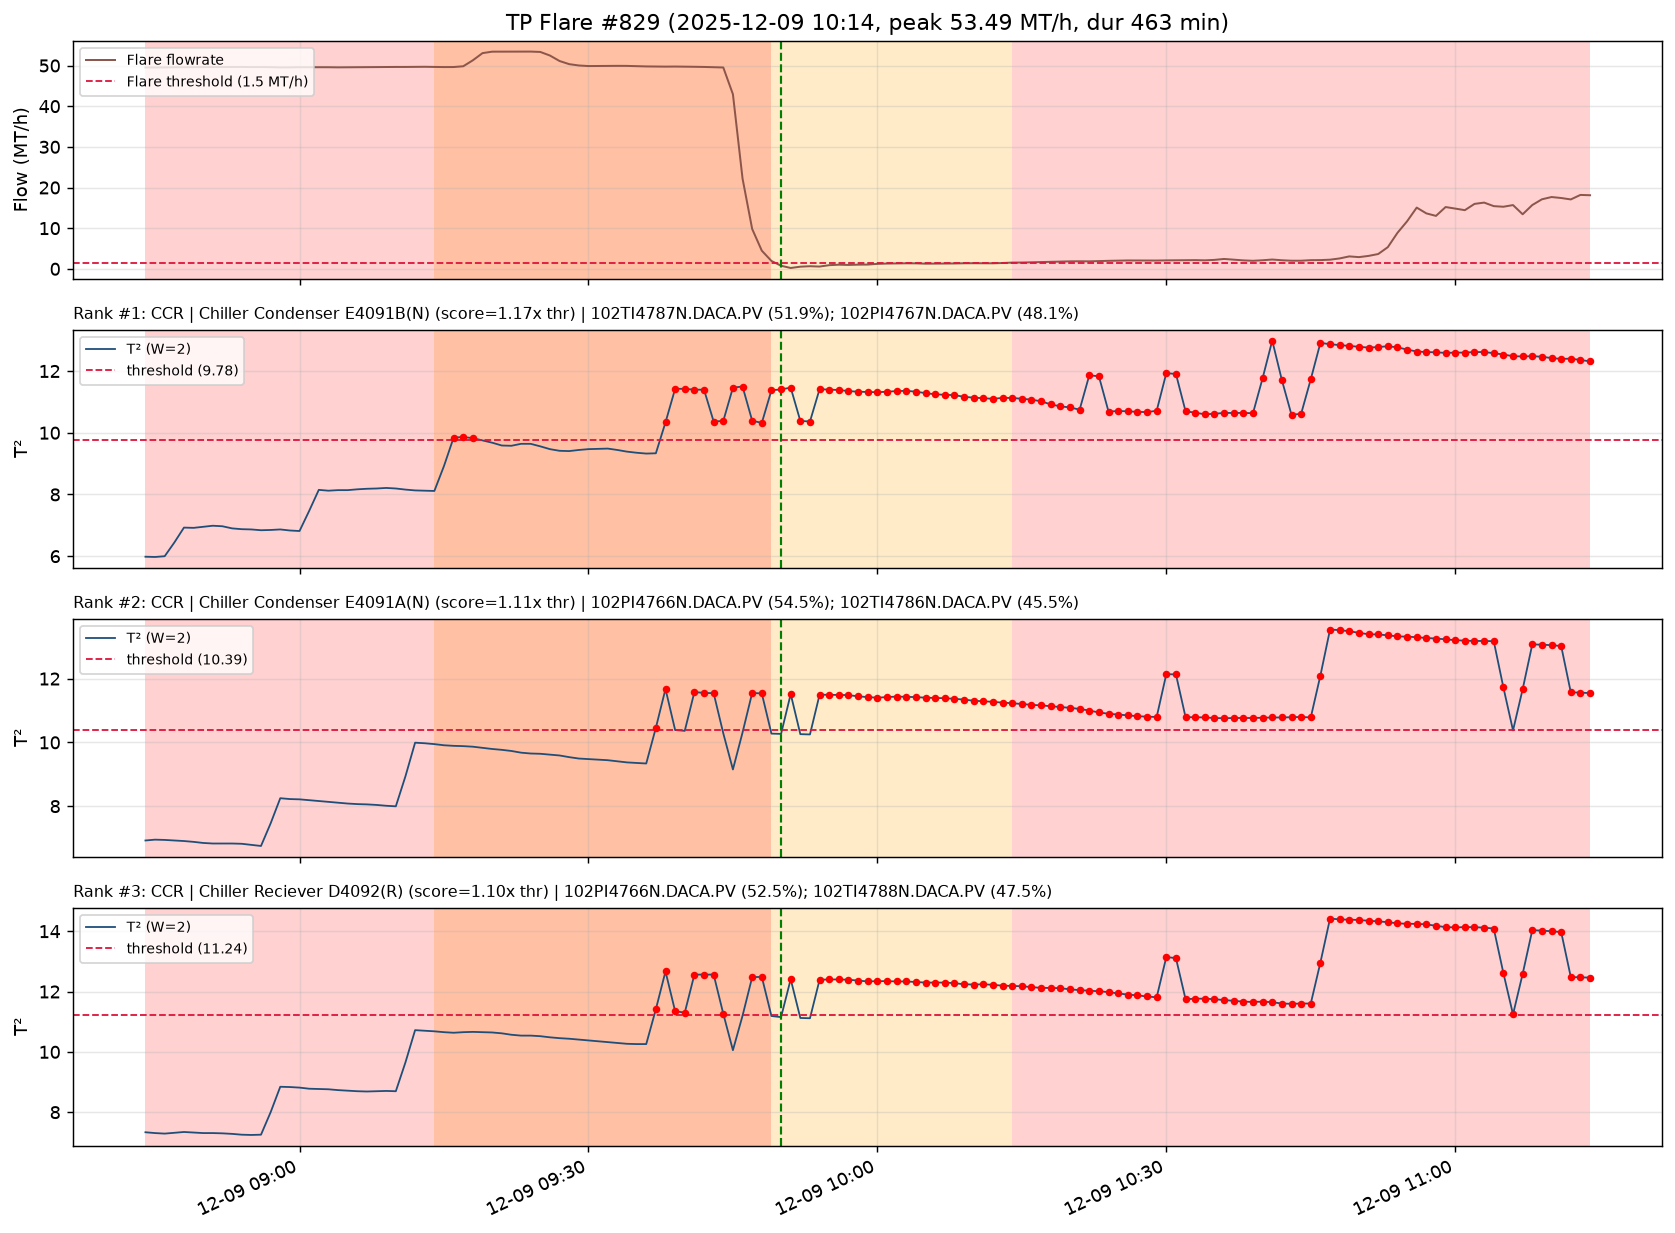

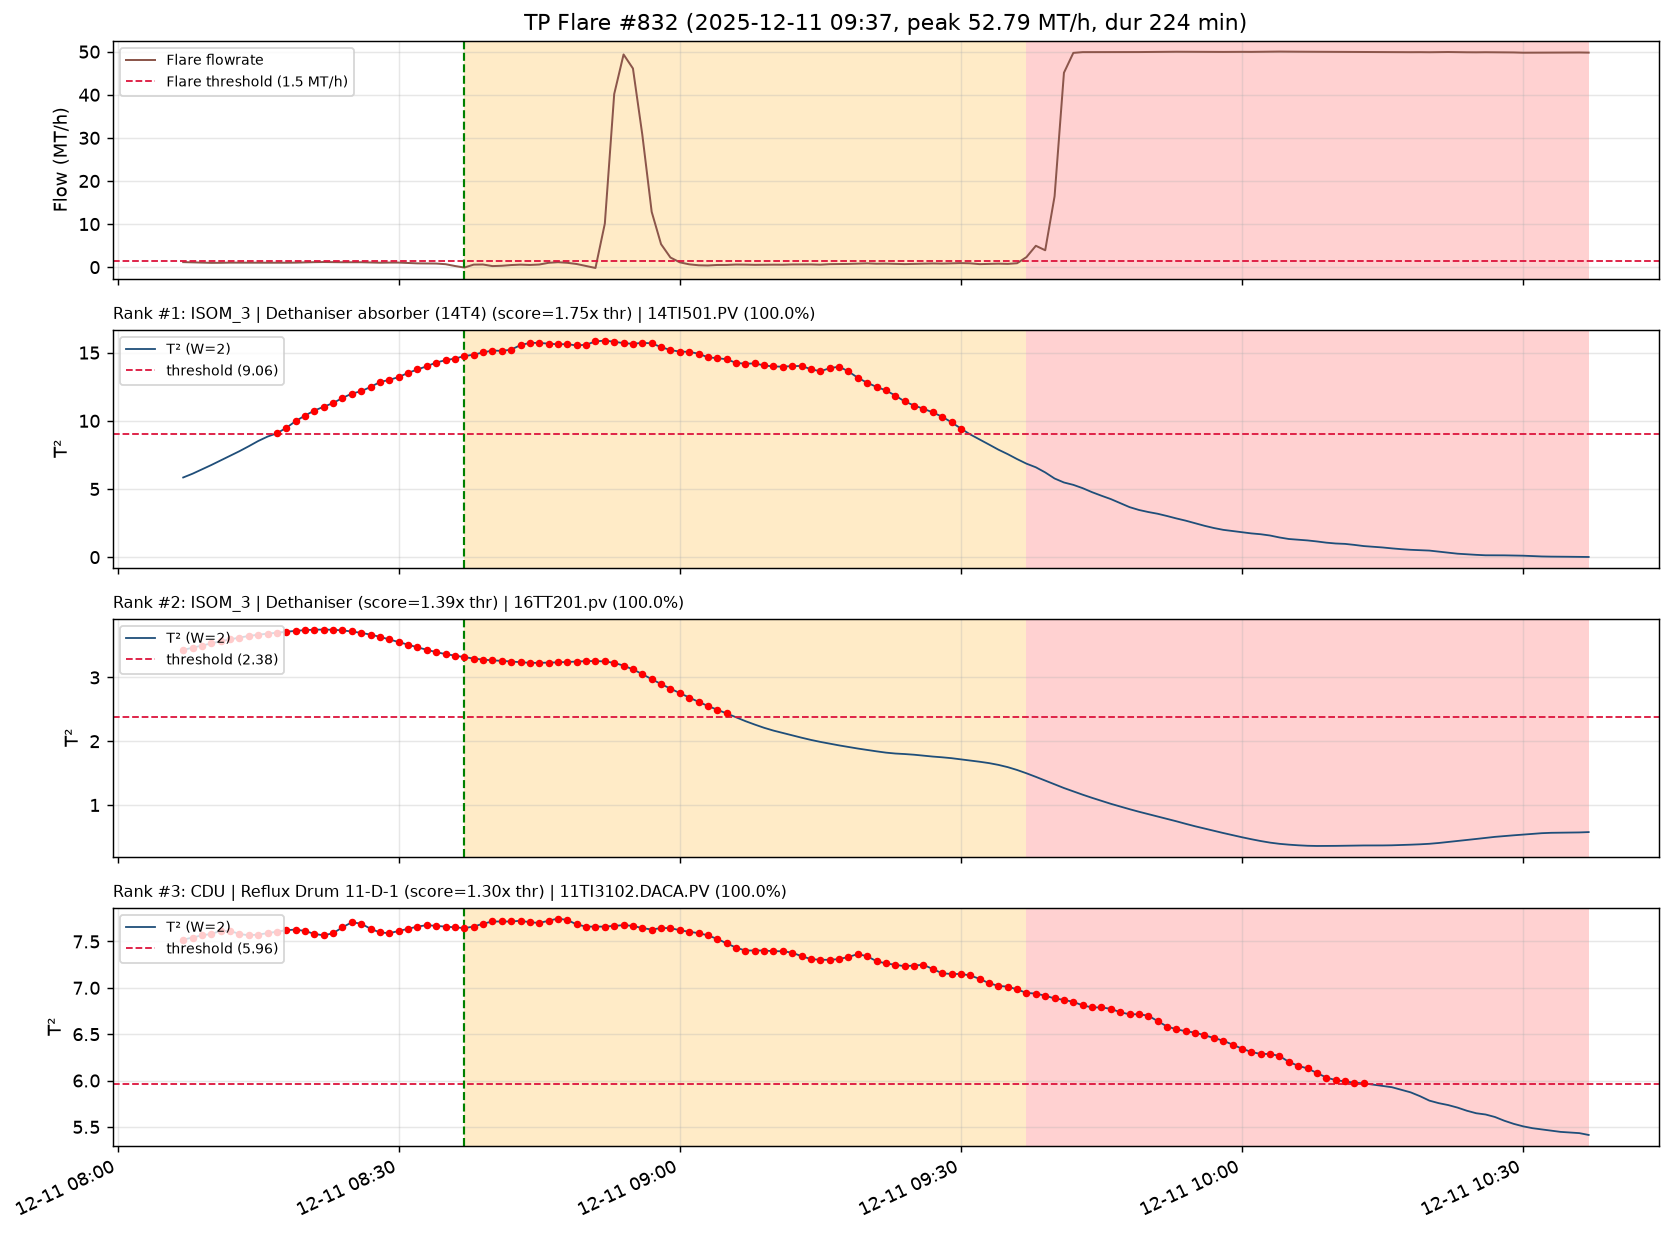

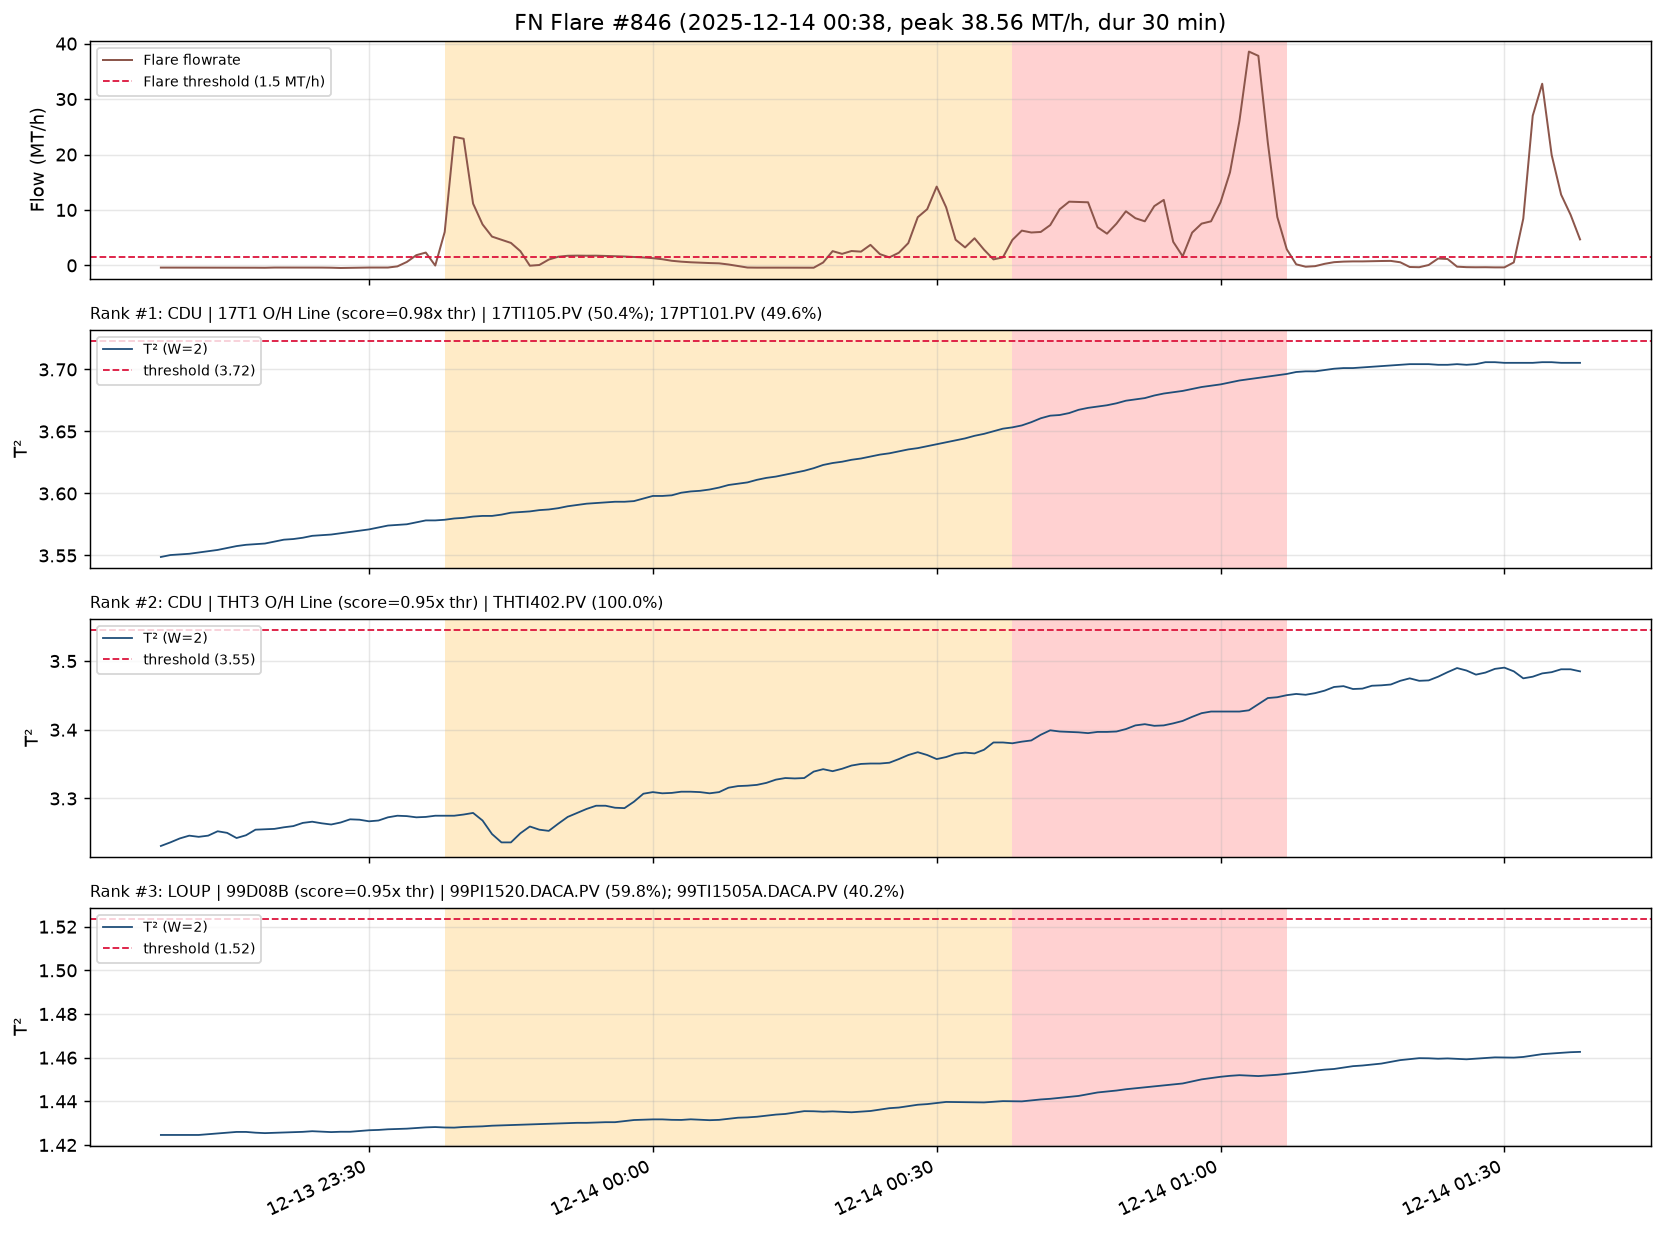

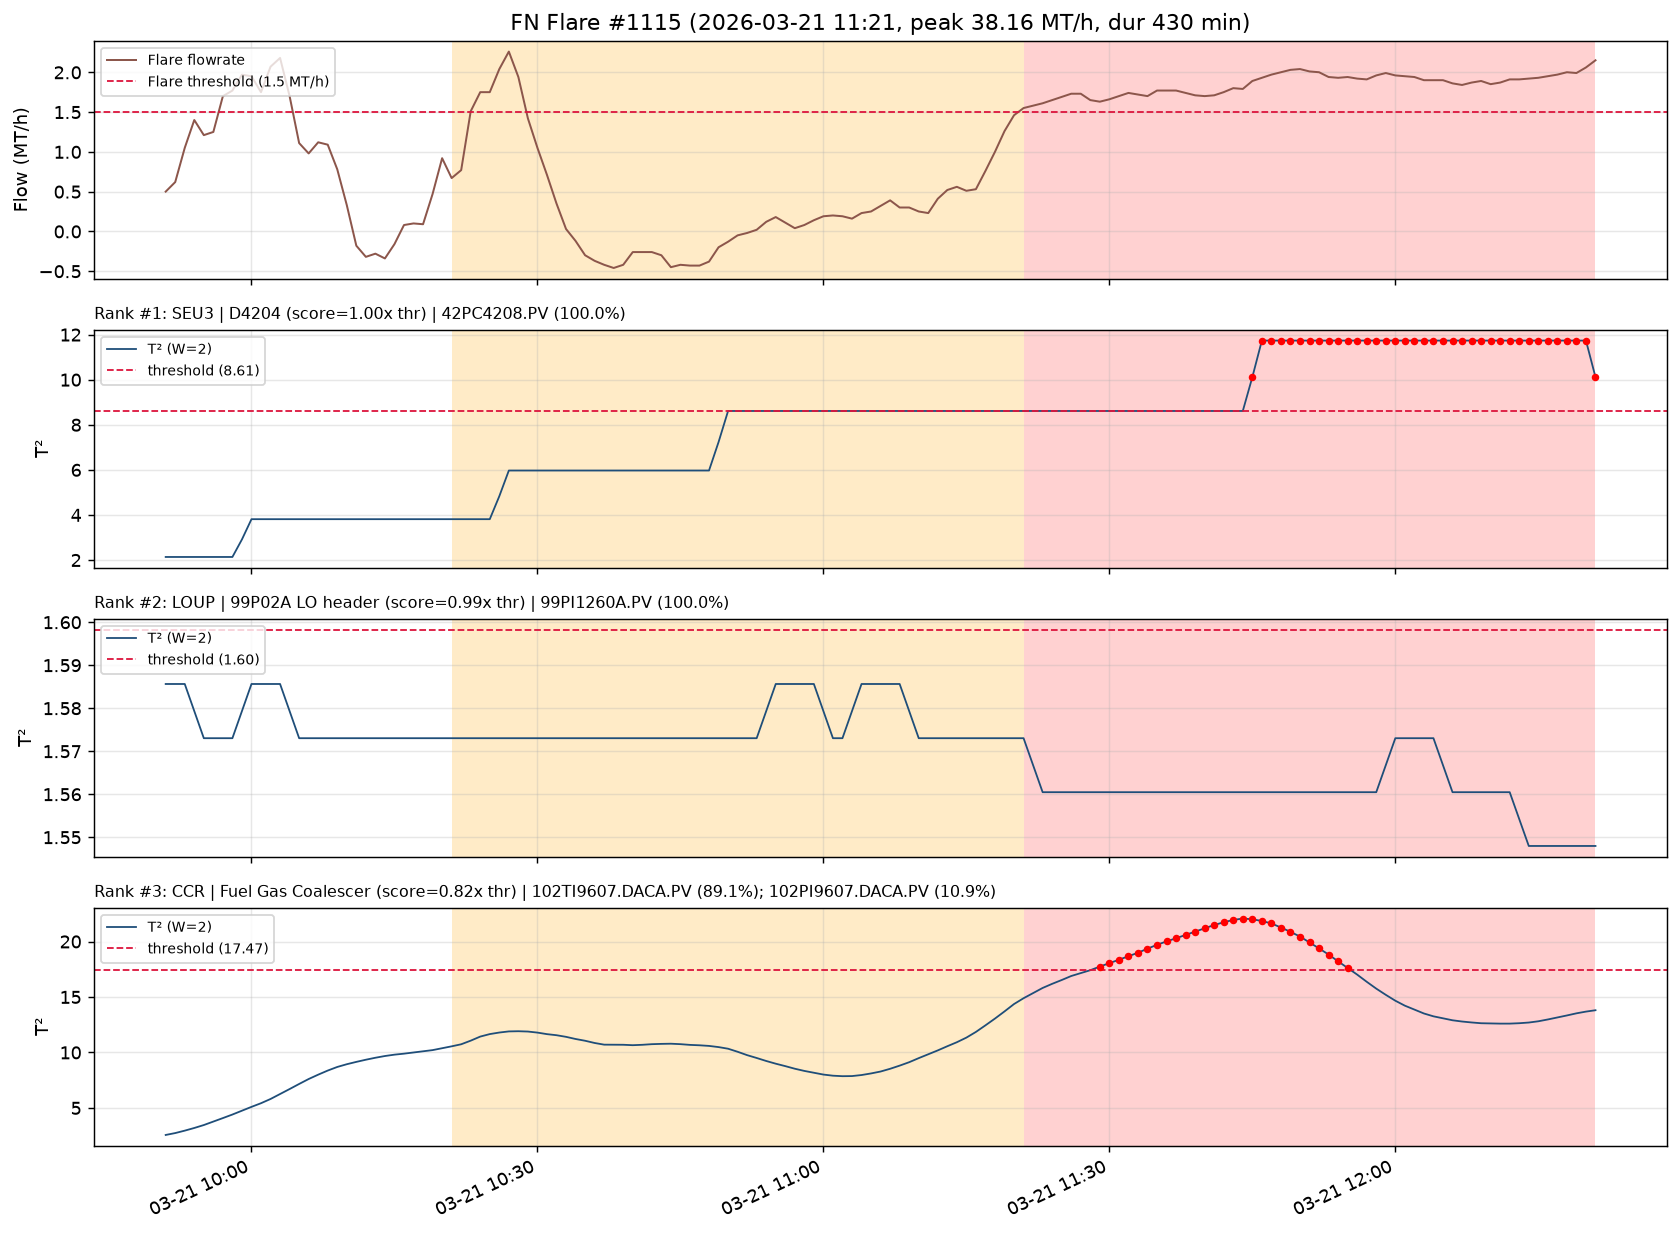

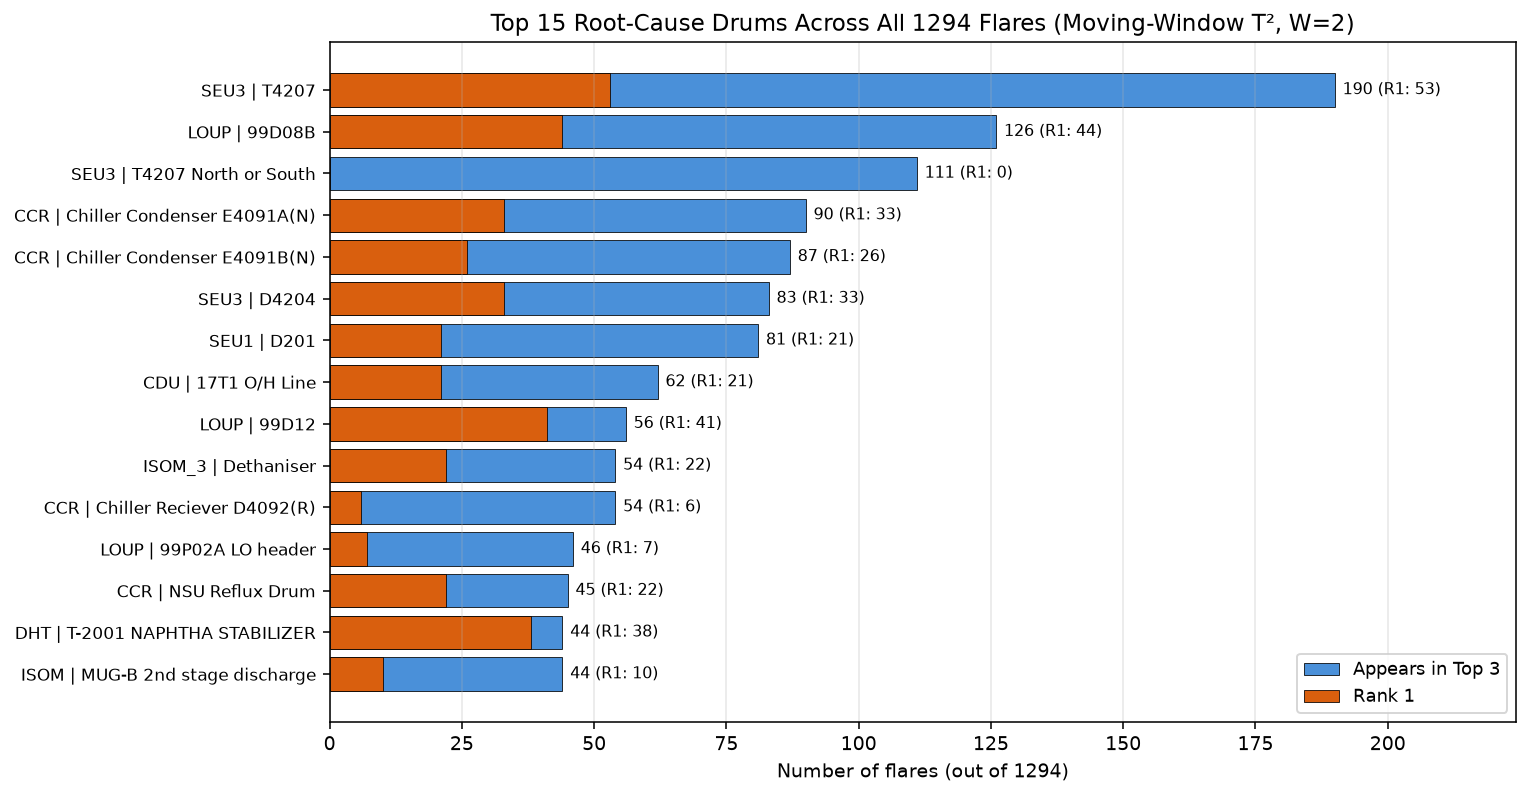

In [36]:
import matplotlib.dates as mdates

t0 = time.time()
flare_s = flare_df.set_index(TS)[FLOW]


def plot_flare_zoom(fi, label):
    e = eval_events.iloc[fi]
    eid = int(e.event_id)
    z0 = e.start - pd.Timedelta(minutes=ZOOM_BEFORE_MIN)
    z1 = e.start + pd.Timedelta(minutes=ZOOM_AFTER_MIN)
    rc_sub = rc_df[rc_df.flare_id == eid].sort_values("rank")
    drums_show = list(rc_sub.drum)
    n_ax = 1 + len(drums_show)
    fig, axes = plt.subplots(n_ax, 1, figsize=(13, 2.4 * n_ax), sharex=True)

    f_sub = flare_s.loc[z0:z1]
    axes[0].plot(f_sub.index, f_sub.values, color="#8c564b", lw=1.1, label="Flare flowrate")
    axes[0].axhline(THRESHOLD, color="crimson", ls="--", lw=1.0, label=f"Flare threshold ({THRESHOLD} MT/h)")
    axes[0].set_ylabel("Flow (MT/h)")
    axes[0].legend(loc="upper left", fontsize=8)
    axes[0].set_title(f"{label} Flare #{eid} ({e.start:%Y-%m-%d %H:%M}, peak {e.peak_flow:.2f} MT/h, dur {e.duration_min:.0f} min)")

    idx_slice = (ts_all >= z0) & (ts_all <= z1)
    t_sub = ts_all[idx_slice]
    for ax, r_row in zip(axes[1:], rc_sub.itertuples(index=False)):
        di = DRUM_NAMES.index(r_row.drum)
        y_sub = T2_MAT[idx_slice, di].astype(float)
        thr = THRESHOLDS[r_row.drum]
        ax.plot(t_sub, y_sub, color="#1f4e79", lw=1.0, label=f"T² (W={T2_WINDOW_SIZE})")
        ax.axhline(thr, color="crimson", ls="--", lw=1.0, label=f"threshold ({thr:.2f})")
        exc = np.isfinite(y_sub) & (y_sub > thr)
        ax.scatter(t_sub[exc], y_sub[exc], s=10, c="red", zorder=3)
        ax.set_ylabel("T²")
        ax.set_title(f"Rank #{r_row.rank}: {r_row.unit} | {r_row.drum} (score={r_row.drum_score:.2f}x thr) | {r_row.top_tags}",
                     loc="left", fontsize=9)
        ax.legend(loc="upper left", fontsize=8)

    pre_0 = e.start - pd.Timedelta(minutes=FLARE_PRE_WINDOW_MIN)
    ev_in_z = eval_events[(eval_events.end >= z0) & (eval_events.start <= z1)]
    for ax in axes:
        ax.axvspan(max(pre_0, z0), min(e.start, z1), color="orange", alpha=0.22, lw=0)
        for ev_z in ev_in_z.itertuples(index=False):
            ax.axvspan(max(ev_z.start, z0), min(ev_z.end, z1), color="red", alpha=0.18, lw=0)
        if np.isfinite(plant_leads[fi]):
            sig_t = e.start - pd.Timedelta(minutes=float(plant_leads[fi]))
            if z0 <= sig_t <= z1:
                ax.axvline(sig_t, color="green", ls="--", lw=1.2)
        ax.grid(alpha=0.3)

    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M"))
    fig.autofmt_xdate(rotation=25)
    fig.tight_layout()
    out_png = OUT_DIR / "t2_plots" / f"flare_zoom_{label}_{eid}.png"
    fig.savefig(out_png, dpi=130, bbox_inches="tight")
    display(Image(filename=str(out_png)))
    plt.close(fig)


tp_idx = np.flatnonzero(plant_det)
fn_idx = np.flatnonzero(~plant_det)
# Pick representative TP flares (with high peak_flow and clean pre-window) and FN flares (with full pre-window)
tp_pick = sorted(tp_idx, key=lambda i: eval_events.peak_flow.iloc[i], reverse=True)[:N_EXAMPLE_ZOOM_PLOTS]
fn_pick = sorted(fn_idx, key=lambda i: (len(pre_slices[i]), eval_events.peak_flow.iloc[i]), reverse=True)[:N_EXAMPLE_ZOOM_PLOTS]

for fi in tp_pick:
    plot_flare_zoom(fi, "TP")
for fi in fn_pick:
    plot_flare_zoom(fi, "FN")

# ---- Bar chart of top root-cause drums across all flares ----
rc_counts = (
    rc_df.assign(label=rc_df["unit"] + " | " + rc_df["drum"], is_rank1=(rc_df["rank"] == 1).astype(int))
    .groupby("label", as_index=False)
    .agg(top3_count=("flare_id", "count"), rank1_count=("is_rank1", "sum"), mean_score=("drum_score", "mean"))
    .sort_values(["top3_count", "rank1_count"], ascending=False)
)
top_bar = rc_counts.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5.8))
y = np.arange(len(top_bar))
ax.barh(y, top_bar["top3_count"], color="#4a90d9", edgecolor="black", lw=0.4, label="Appears in Top 3")
ax.barh(y, top_bar["rank1_count"], color="#d95f0e", edgecolor="black", lw=0.4, label="Rank 1")
ax.set_yticks(y)
ax.set_yticklabels(top_bar["label"], fontsize=8.5)
for yi, (_, row) in enumerate(top_bar.iterrows()):
    ax.annotate(f"{int(row.top3_count)} (R1: {int(row.rank1_count)})",
                (row.top3_count, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_xlabel(f"Number of flares (out of {len(eval_events)})")
ax.set_xlim(0, top_bar["top3_count"].max() * 1.18)
ax.set_title(f"Top 15 Root-Cause Drums Across All {len(eval_events)} Flares (Moving-Window T², W={T2_WINDOW_SIZE})")
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
rc_bar_path = OUT_DIR / "t2_plots" / "top_root_cause_drums.png"
fig.savefig(rc_bar_path, dpi=140, bbox_inches="tight")
display(Image(filename=str(rc_bar_path)))
plt.close(fig)
STAGE_TIMES["9 zoom & RC plots"] = time.time() - t0


## Step 10 - Analysis & Assumptions

*(To be populated with observed metrics and findings after end-to-end execution.)*


## Summary of outputs

In [37]:
skipped = pca_table[pca_table.n_PCs == 0]
print(f"units: {len(unit_drums)} | drums in JSON: {len(drum_tags)} | drums modelled: {len(MODELS)} | skipped: {len(skipped)}")
if len(skipped):
    display(skipped[["unit", "drum", "flag", "dropped_tags"]])
print(f"PC algorithm: one graph over {len(pc_nodes)} PCs, {len(EDGES)} edges "
      f"({edges_df.scope.value_counts().to_dict()}); PCs left out before PC: {len(pc_drops)}")
print(f"Meek rules: {MEEK_INFO['passes']} pass(es)" + (f", STOPPED EARLY: {MEEK_INFO['stopped']}" if MEEK_INFO["stopped"] else ""))
for p in ["flare_mask.parquet", "drum_pca_summary.csv", "drum_pc_graph_summary.csv", "pc_edges.csv",
          "pc_edges_unit_by_unit.csv", "pc_dropped_nodes.csv", "t2_index.csv",
          "confusion_matrix_overall.csv", "confusion_matrix_per_unit.csv", "confusion_matrix_per_drum.csv",
          "flare_detection_events.csv", "false_alarm_episodes.csv", "sensitivity_analysis.csv",
          "root_causes.csv", "root_causes.json"]:
    print(f"  outputs/{p}")
for sub in ["graphs_json", "graphs_png", "t2", "t2_plots", "checkpoints"]:
    files = list((OUT_DIR / sub).rglob("*.*"))
    print(f"  outputs/{sub}/  {len(files)} files")
print("\ntime per stage (s):", {k: round(v, 1) for k, v in STAGE_TIMES.items()})
print(f"total since the config cell: {(time.time() - RUN_T0) / 60:.1f} min")


units: 13 | drums in JSON: 301 | drums modelled: 251 | skipped: 50


,unit,drum,flag,dropped_tags
2,SEU3,D4205,SKIPPED: no usable tag,42PI4213.PV
20,SEU1,C401C D/C,SKIPPED: no usable tag,04PI421C.PV
21,SEU1,D209,SKIPPED: no usable tag,02PI206.PV
24,SEU1,D205,SKIPPED: no usable tag,02PI213.PV
25,SEU1,D207,SKIPPED: no usable tag,LHC215.PV
27,SEU1,D208,SKIPPED: no usable tag,LHC222.PV
28,SEU1,R201,SKIPPED: no usable tag,02PDI215.PV
29,SEU1,E207 O/L,SKIPPED: no usable tag,02PI221B.PV
40,SEU1,GR201,SKIPPED: no usable tag,02PDI215.PV
45,SEU2,D3207,SKIPPED: no usable tag,PPI3241.PV


PC algorithm: one graph over 254 PCs, 984 edges ({'cross unit': 612, 'within unit': 372}); PCs left out before PC: 75
Meek rules: n/a pass(es)
  outputs/flare_mask.parquet
  outputs/drum_pca_summary.csv
  outputs/drum_pc_graph_summary.csv
  outputs/pc_edges.csv
  outputs/pc_edges_unit_by_unit.csv
  outputs/pc_dropped_nodes.csv
  outputs/t2_index.csv
  outputs/confusion_matrix_overall.csv
  outputs/confusion_matrix_per_unit.csv
  outputs/confusion_matrix_per_drum.csv
  outputs/flare_detection_events.csv
  outputs/false_alarm_episodes.csv
  outputs/sensitivity_analysis.csv
  outputs/root_causes.csv
  outputs/root_causes.json
  outputs/graphs_json/  265 files
  outputs/graphs_png/  265 files
  outputs/t2/  252 files
  outputs/t2_plots/  257 files
  outputs/checkpoints/  2 files

time per stage (s): {'3 PCA': 0.1, '4a input': 0.1, '4b-4d vectorized PC': 7.9, '4e outputs': 0.3, '5 graph figures': 17.0, '6 T2 files': 9.5, '6 T2 plots': 0.0, '7 detection & CM': 21.0, '7b sensitivity': 113.1, 